In [1]:
%load_ext autoreload
%autoreload 2

import os
from glob import glob
from PIL import Image
from IPython.display import display
from tqdm.notebook import tqdm
import sys
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.io as sio
import torch
import torchvision as tv

from compcats.models import resnet50_random, resnet50_imagenet1kv2, resnet50_openaiclip
from compcats.datasets.image import custom
from compcats.datasets.fmri import murty185
from compcats.utils import model_utils, reliability_utils as rel_utils

sys.path.append('../preprint')
from preprint import paths
from preprint import main_analysis as ma

RESULTS_DIR = 'results'
os.makedirs(RESULTS_DIR, exist_ok=True)
PLOTS_DIR = 'plots'
os.makedirs(PLOTS_DIR, exist_ok=True)

MODELS_DIR = '/Users/adipani3/projects/catsel/comparing-category-selectivity/preprint/models'

pixdim[1,2,3] should be non-zero; setting 0 dims to 1


# Data inspecttion

## Processing

### General

In [ ]:
data_dir = '/Users/adipani3/datasets/intracranial'
assert os.path.exists(os.path.join(data_dir, 'processed')), f'{data_dir}/processed does not exist'
h5_data_dir = f'{data_dir}/processed/h5'
h5_files = sorted(glob(os.path.join(h5_data_dir, '*.h5')))
assert len(h5_files) > 0, f'No .h5 files found in {h5_data_dir}'

# Image ordering of the original Murty185 stimuli (1-based indexing)
image_info_df = pd.read_csv(f'{data_dir}/processed/image_info.csv')
# stimuli_original_murty185_mapping = np.zeros(len(image_info_df), dtype=int)
# # Create mapping from intracrianl data order to original murty185 order
# for i, row in image_info_df.iterrows():
#     original_image_name = row['original_image_name']
#     original_image_idx_1indexed = int(original_image_name.split('.')[0].replace('image', ''))
#     stimuli_original_murty185_mapping[original_image_idx_1indexed-1] = i
original_order = image_info_df['original_image_name'].str.extract(r'(\d+)').astype(int).squeeze()
stimuli_original_murty185_mapping = np.argsort(original_order.values)


Y = {}
for h5_file in h5_files:
    filename = h5_file.split('/')[-1].split('.')[0]
    file_label = '_'.join(filename.split('_')[1:4])  # e.g. A1_D3_set1
    if file_label == 'A1_D3_set1':
        print(f'Skipping file label: {file_label}')
        continue
    setnumber = int(file_label.split('_')[2].replace('set', ''))  # Extract set number (e.g., 'set1')
    Y_ = {} # Initialize a dict for this file's data
    with h5py.File(h5_file, 'r') as f:
        # Quick exploration commands:
        # 1. List all channels
        print(f'Processing file label: {file_label}')
        channels = list(f.keys())
        print(f"Channels: {channels[:5]}... (total: {len(channels)})")

        for channel in channels:
            spikes = list(f[channel].keys())
            for spike in spikes:
                data_ = f[f'{channel}/{spike}'][:]  # (186, 70, 9)
                # Remove the first image (fixation cross)
                if setnumber==1:
                    data_ = data_[1:186, :, :]
                # if file_label == 'A1_D3_set1':
                #     assert data_.shape[0] == 184, f"Unexpected shape for {channel}/{spike}: {data_.shape}"
                # else:
                #     assert data_.shape[0] == 185, f"Unexpected shape for {channel}/{spike}: {data_.shape}"
                # Transpose to (185, 9, 70), i.e. images x n_reps x n_timebins
                data_ = data_.transpose(0, 2, 1)
                # # Order in the original Murty185 ordering
                # if file_label == 'A1_D3_set1':
                #     missing_image_info = image_info_df[image_info_df['stimulus_image_name'] == '156.bmp']  # This is the missing image im156
                #     image_info_df2 = image_info_df.copy()
                #     image_info_df2 = image_info_df2[image_info_df2['stimulus_image_name'] != '156.bmp']  # Remove the row corresponding to the missing image im156
                #     original_order = image_info_df2['original_image_name'].str.extract(r'(\d+)').astype(int).squeeze()
                #     stimuli_original_murty185_mapping_corrected = np.argsort(original_order.values)
                #     data_ = data_[stimuli_original_murty185_mapping_corrected]
                # else:
                #     data_ = data_[stimuli_original_murty185_mapping]
                if setnumber == 1 or file_label == 'A2_D3a_set6':
                    data_ = data_[stimuli_original_murty185_mapping]
                # TODO: Implement renaming
                # if file_label == 'A2_D3a_set6':
                #     file_label = 'A2_D3a_set1'
                #     print(f'Renaming A2_D3a_set6 to A2_D3a_set1')
                if np.isnan(data_).all():
                    print(f"Skipping {channel}/{spike}: all NaNs")
                    continue
                if np.sum(np.isnan(data_)) > np.size(data_)*0.99:
                    print(f"Skipping {channel}/{spike}: more than 99% NaNs")
                    continue
                Y_[f'{channel.replace("_", "=")}_{spike.replace("_", "=")}'] = {
                    'data': data_,
                    'label': 'MUA' if spike == 'spike_001' else 'SUA'
                }

    Y[file_label] = Y_
    # Sort keys, bring all spike=001 at first, i.e. ch=001_spike=001, ch=002_spike=001...
    Y_MUAs, Y_SUAs = {},  {}
    for key, value in Y_.items():
        if key.split('_')[-1] == 'spike=001':
            Y_MUAs[key] = value
        else:
            Y_SUAs[key] = value
    Y_sorted = {**Y_MUAs, **Y_SUAs}

    Y_array = [value['data'] for value in Y_sorted.values()]
    Y_array = np.stack(Y_array)

    np.save(f'{data_dir}/processed/NetSpikeRate_{file_label}_combined_10ms_Z_norm_per_channel_interval.npy', Y_array)

    # Convert labels info a df
    labels = [value['label'] for value in Y_sorted.values()]
    keys = [key for key in Y_sorted.keys()]
    source_df = pd.DataFrame({'key': keys, 'label': labels})
    source_df.to_csv(f'{data_dir}/processed/{file_label}_source_info.csv', index=False)
    print('\n')

### Load data

In [17]:
data_dir = '/Users/adipani3/datasets/intracranial'
processed_data_dir = os.path.join(data_dir, 'processed')
assert os.path.exists(processed_data_dir), f'{data_dir}/processed does not exist'
npy_files = sorted(glob(os.path.join(processed_data_dir, '*.npy')))
assert len(npy_files) > 0, f'No .npy files found in {processed_data_dir}'

In [18]:
npy_files

['/Users/adipani3/datasets/intracranial/processed/NetSpikeRate_A1_D12_set1_combined_10ms_Z_norm_per_channel_interval.npy',
 '/Users/adipani3/datasets/intracranial/processed/NetSpikeRate_A2_D3a_set1_combined_10ms_Z_norm_per_channel_interval.npy',
 '/Users/adipani3/datasets/intracranial/processed/NetSpikeRate_A4_D14_set8_combined_10ms_Z_norm_per_channel_interval.npy',
 '/Users/adipani3/datasets/intracranial/processed/NetSpikeRate_A4_D4_set1_combined_10ms_Z_norm_per_channel_interval.npy',
 '/Users/adipani3/datasets/intracranial/processed/NetSpikeRate_A4_D6_set7_combined_10ms_Z_norm_per_channel_interval.npy',
 '/Users/adipani3/datasets/intracranial/processed/NetSpikeRate_A4_D8_set5_combined_10ms_Z_norm_per_channel_interval.npy',
 '/Users/adipani3/datasets/intracranial/processed/NetSpikeRate_A5_D9_set1_combined_10ms_Z_norm_per_channel_interval.npy']

In [22]:
npy_file = npy_files[0]
filename = npy_file.split('/')[-1].split('.')[0]
file_label = '_'.join(filename.split('_')[1:4])  # e.g. A1_D3_set1
y_array = np.load(npy_file)

In [23]:
y_array.shape

(100, 185, 56, 70)

In [2]:
data_dir = '/Users/adipani3/datasets/intracranial'
processed_data_dir = os.path.join(data_dir, 'processed')
assert os.path.exists(processed_data_dir), f'{data_dir}/processed does not exist'
npy_files = sorted(glob(os.path.join(processed_data_dir, '*.npy')))
assert len(npy_files) > 0, f'No .npy files found in {processed_data_dir}'

# # Image ordering of the original Murty185 stimuli (1-based indexing)
# image_info_df = pd.read_csv(f'{processed_data_dir}/image_info.csv')
# # stimuli_original_murty185_mapping = np.zeros(len(image_info_df), dtype=int)
# # # Create mapping from intracrianl data order to original murty185 order
# # for i, row in image_info_df.iterrows():
# #     original_image_name = row['original_image_name']
# #     original_image_idx_1indexed = int(original_image_name.split('.')[0].replace('image', ''))
# #     stimuli_original_murty185_mapping[original_image_idx_1indexed-1] = i
# original_order = image_info_df['original_image_name'].str.extract(r'(\d+)').astype(int).squeeze()
# stimuli_original_murty185_mapping = np.argsort(original_order.values)


Y_arrays = {}
Y_sources = {}
for npy_file in npy_files:
    filename = npy_file.split('/')[-1].split('.')[0]
    filelabel = '_'.join(filename.split('_')[1:4])  # e.g. A1_D3_set1
    setnumber = int(filelabel.split('_')[2].replace('set', ''))  # Extract set number (e.g., 'set1')
    if filelabel == 'A1_D3_set1' or setnumber != 1:
        print(f'Skipping file label: {filelabel}')
        continue
    y_array = np.load(npy_file)
    # Set 1, so assert number of images
    assert y_array.ndim == 4, "Expected 4 dimensions: (sources (mua/sua), images, reps, timebins)"
    assert y_array.shape[1] == 185, f"Expected 185 images in {filelabel}"
    source_labels_df = pd.read_csv(f'{processed_data_dir}/{filelabel}_source_info.csv')
    source_labels = list(source_labels_df['label'].values)
    Y_arrays[filelabel] = y_array
    Y_sources[filelabel] = np.array(source_labels)
    print(f'Loaded file label: {filelabel}')

Loaded file label: A1_D12_set1
Loaded file label: A2_D3a_set1
Skipping file label: A4_D14_set8
Loaded file label: A4_D4_set1
Skipping file label: A4_D6_set7
Skipping file label: A4_D8_set5
Loaded file label: A5_D9_set1


## Reliabilities

In [3]:
considered_data = ['A1_D12_set1', 'A2_D3a_set6', 'A4_D4_set1', 'A5_D9_set1']

# Bin: 50-300 ms
relaibilities_binned = {}
source_labels_dict = {}
for key in considered_data:
    value = Y[key]
    Y_array = [value_['data'] for value_ in value.values()]
    Y_array = torch.tensor(np.stack(Y_array))
    bin_data = np.nanmean(Y_array[:, :, :, 35:60], axis=-1)
    print(f'Processing {key}, shape: {bin_data.shape}')
    relaibilities_binned[key], _ = rel_utils.get_neuron_wise_splithalf_correlation(bin_data)
    source_df = pd.read_csv(f'{data_dir}/processed/{key}_source_info.csv')
    source_labels_dict[key] = source_df['label'].values
    print(f'Processed {key}, reliability shape: {relaibilities_binned[key].shape}\n\n')

# For each bin type, plot a boxplot for reliabilities
# Also plot a scatter plot of points, and color based on the label (MUA/SUA)
plt.figure(figsize=(9, 6))
bin_labels = list(relaibilities_binned.keys())
colors_dict = {'MUA': 'blue', 'SUA': 'red'}
x_positions = np.arange(len(bin_labels))
# Boxplots (all sites combined) in one axis
box_data = [relaibilities_binned[bl] for bl in bin_labels]
plt.boxplot(box_data, positions=x_positions, widths=0.25, showfliers=False, medianprops=dict(color='black'))

# Overlay scatter points, colored by MUA/SUA
xticklabels = []
for i, bl in enumerate(bin_labels):
    vals = relaibilities_binned[bl]
    xticklabel = bl
    for lab in ['MUA', 'SUA']:
        mask = source_labels_dict[bl] == lab
        x_jitter = np.random.normal(loc=i, scale=0.03, size=mask.sum())
        plt.scatter(
            x_jitter,
            vals[mask],
            s=18,
            alpha=0.6,
            color=colors_dict[lab],
            label=lab if i == 0 else None
        )
        n_valid_sites = np.sum(vals[mask]>0)
        xticklabel += f'\n{n_valid_sites} valid {lab}s'
    xticklabels.append(xticklabel)
plt.axhline(y=0, color='k', linestyle='--', alpha=0.5)
# plt.axhline(y=0.1, color='gray', linestyle='-', alpha=0.5)
plt.xticks(x_positions, xticklabels, rotation=20, ha='right')
plt.ylabel('SPearman-brown corrected split-half reliabilities (100 bootstraps)')
plt.ylim(-0.4, 1.0)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.gca().spines['left'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_bounds(0, 3)
plt.legend(frameon=False)
plt.tight_layout()
plt.show()

NameError: name 'Y' is not defined

In [10]:
relaibilities_binned[key]

array([ 1.70830897e-02, -8.60210643e-05,  4.46514339e-03, -4.17375606e-03,
       -3.27557428e-03,  3.44884079e-04, -2.12415894e-03, -1.81698241e-03,
       -6.44744231e-04,  3.36320098e-03, -2.86858421e-03, -8.13842079e-02,
        2.47244188e-03, -7.08528077e-02, -4.01401092e-03, -1.65154724e-01,
       -3.71551455e-03,  1.10913812e-01, -2.12486908e-03,  1.92787673e-01,
       -1.52686693e-03,  5.54821196e-02, -1.15018385e-01,  7.37182069e-02,
       -3.13921387e-03,  4.98221681e-02,  9.64955333e-04, -3.70494978e-03,
        4.61999499e-01,  5.77937011e-03, -3.18155742e-03, -4.86167759e-02,
        6.89916290e-02,  1.91421961e-01, -1.93820349e-01, -5.54661110e-03,
        8.00229919e-03, -6.61023085e-03, -7.69583515e-02,  5.02767682e-02,
        2.25161679e-01,  2.35210197e-01,  2.18630330e-01,  1.18757220e-01,
       -5.93983621e-02,  5.47826795e-02, -1.83859878e-01, -2.01222588e-01,
        1.82235213e-01,  3.33302422e-01, -8.97773154e-03,  5.03406729e-01,
        1.43186576e-02,  

In [5]:
bin_data.shape

(112, 185, 8)

/var/folders/f4/jrx4_ljx4_q3d25kvtsnw4tw0000gq/T/ipykernel_51600/3982271341.py:8: RuntimeWarning: Mean of empty slice
  bin_data = np.nanmean(Y_array[:, :, :, 35:60], axis=-1)


Processing A1_D12_set1, shape: (100, 185, 56)
Reducing number of repeats from 56 to 10 for split-half reliability estimation
Processing A2_D3a_set1, shape: (147, 185, 22)
Reducing number of repeats from 22 to 20 for split-half reliability estimation
Processing A4_D4_set1, shape: (155, 185, 9)
Processing A5_D9_set1, shape: (112, 185, 8)


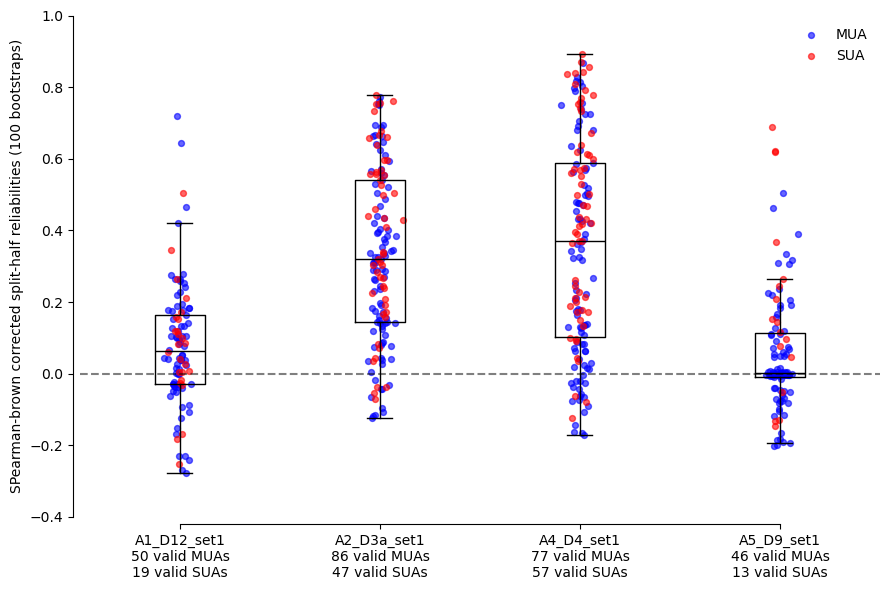

In [4]:
considered_data = ['A1_D12_set1', 'A2_D3a_set1', 'A4_D4_set1', 'A5_D9_set1']

# Bin: 50-300 ms
relaibilities_binned = {}
source_labels_dict = {}
for key in considered_data:
    Y_array = torch.tensor(Y_arrays[key])
    bin_data = np.nanmean(Y_array[:, :, :, 35:60], axis=-1)
    print(f'Processing {key}, shape: {bin_data.shape}')
    relaibilities_binned[key], _ = rel_utils.get_neuron_wise_splithalf_correlation(bin_data)
    # source_df = pd.read_csv(f'{data_dir}/processed/{key}_source_info.csv')
    # source_labels_dict[key] = source_df['label'].values
    # print(f'Processed {key}, reliability shape: {relaibilities_binned[key].shape}\n\n')

# For each bin type, plot a boxplot for reliabilities
# Also plot a scatter plot of points, and color based on the label (MUA/SUA)
plt.figure(figsize=(9, 6))
bin_labels = list(relaibilities_binned.keys())
colors_dict = {'MUA': 'blue', 'SUA': 'red'}
x_positions = np.arange(len(bin_labels))
# Boxplots (all sites combined) in one axis
box_data = [relaibilities_binned[bl] for bl in bin_labels]
plt.boxplot(box_data, positions=x_positions, widths=0.25, showfliers=False, medianprops=dict(color='black'))

# Overlay scatter points, colored by MUA/SUA
xticklabels = []
for i, bl in enumerate(bin_labels):
    vals = relaibilities_binned[bl]
    xticklabel = bl
    for lab in ['MUA', 'SUA']:
        mask = Y_sources[bl] == lab
        x_jitter = np.random.normal(loc=i, scale=0.03, size=mask.sum())
        plt.scatter(
            x_jitter,
            vals[mask],
            s=18,
            alpha=0.6,
            color=colors_dict[lab],
            label=lab if i == 0 else None
        )
        n_valid_sites = np.sum(vals[mask]>0)
        xticklabel += f'\n{n_valid_sites} valid {lab}s'
    xticklabels.append(xticklabel)
plt.axhline(y=0, color='k', linestyle='--', alpha=0.5)
# plt.axhline(y=0.1, color='gray', linestyle='-', alpha=0.5)
plt.xticks(x_positions, xticklabels, rotation=20, ha='right')
plt.ylabel('SPearman-brown corrected split-half reliabilities (100 bootstraps)')
plt.ylim(-0.4, 1.0)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.gca().spines['left'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_bounds(0, 3)
plt.legend(frameon=False)
plt.tight_layout()
plt.show()

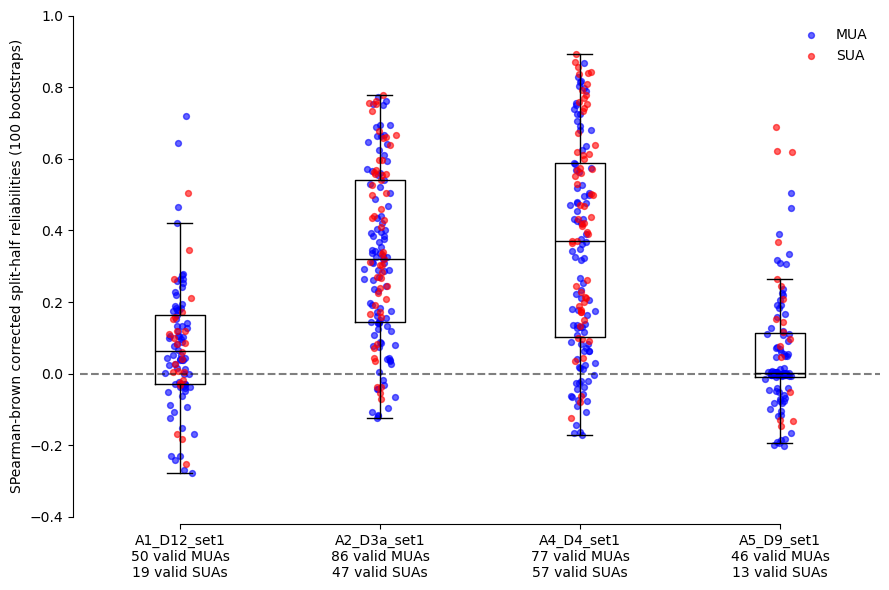

In [11]:
# For each bin type, plot a boxplot for reliabilities
# Also plot a scatter plot of points, and color based on the label (MUA/SUA)
plt.figure(figsize=(9, 6))
bin_labels = list(relaibilities_binned.keys())
colors_dict = {'MUA': 'blue', 'SUA': 'red'}
x_positions = np.arange(len(bin_labels))
# Boxplots (all sites combined) in one axis
box_data = [relaibilities_binned[bl] for bl in bin_labels]
plt.boxplot(box_data, positions=x_positions, widths=0.25, showfliers=False, medianprops=dict(color='black'))

# Overlay scatter points, colored by MUA/SUA
xticklabels = []
for i, bl in enumerate(bin_labels):
    vals = relaibilities_binned[bl]
    xticklabel = bl
    for lab in ['MUA', 'SUA']:
        mask = Y_sources[bl] == lab
        x_jitter = np.random.normal(loc=i, scale=0.03, size=mask.sum())
        plt.scatter(
            x_jitter,
            vals[mask],
            s=18,
            alpha=0.6,
            color=colors_dict[lab],
            label=lab if i == 0 else None
        )
        n_valid_sites = np.sum(vals[mask]>0)
        xticklabel += f'\n{n_valid_sites} valid {lab}s'
    xticklabels.append(xticklabel)
plt.axhline(y=0, color='k', linestyle='--', alpha=0.5)
# plt.axhline(y=0.1, color='gray', linestyle='-', alpha=0.5)
plt.xticks(x_positions, xticklabels, rotation=20, ha='right')
plt.ylabel('SPearman-brown corrected split-half reliabilities (100 bootstraps)')
plt.ylim(-0.4, 1.0)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.gca().spines['left'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_bounds(0, 3)
plt.legend(frameon=False)
plt.tight_layout()
plt.show()

## Response dynamics

Plotting A1_D12_set1 with 102 channels
Plotting A2_D3a_set6 with 147 channels
Plotting A4_D4_set1 with 155 channels
Plotting A5_D9_set1 with 112 channels


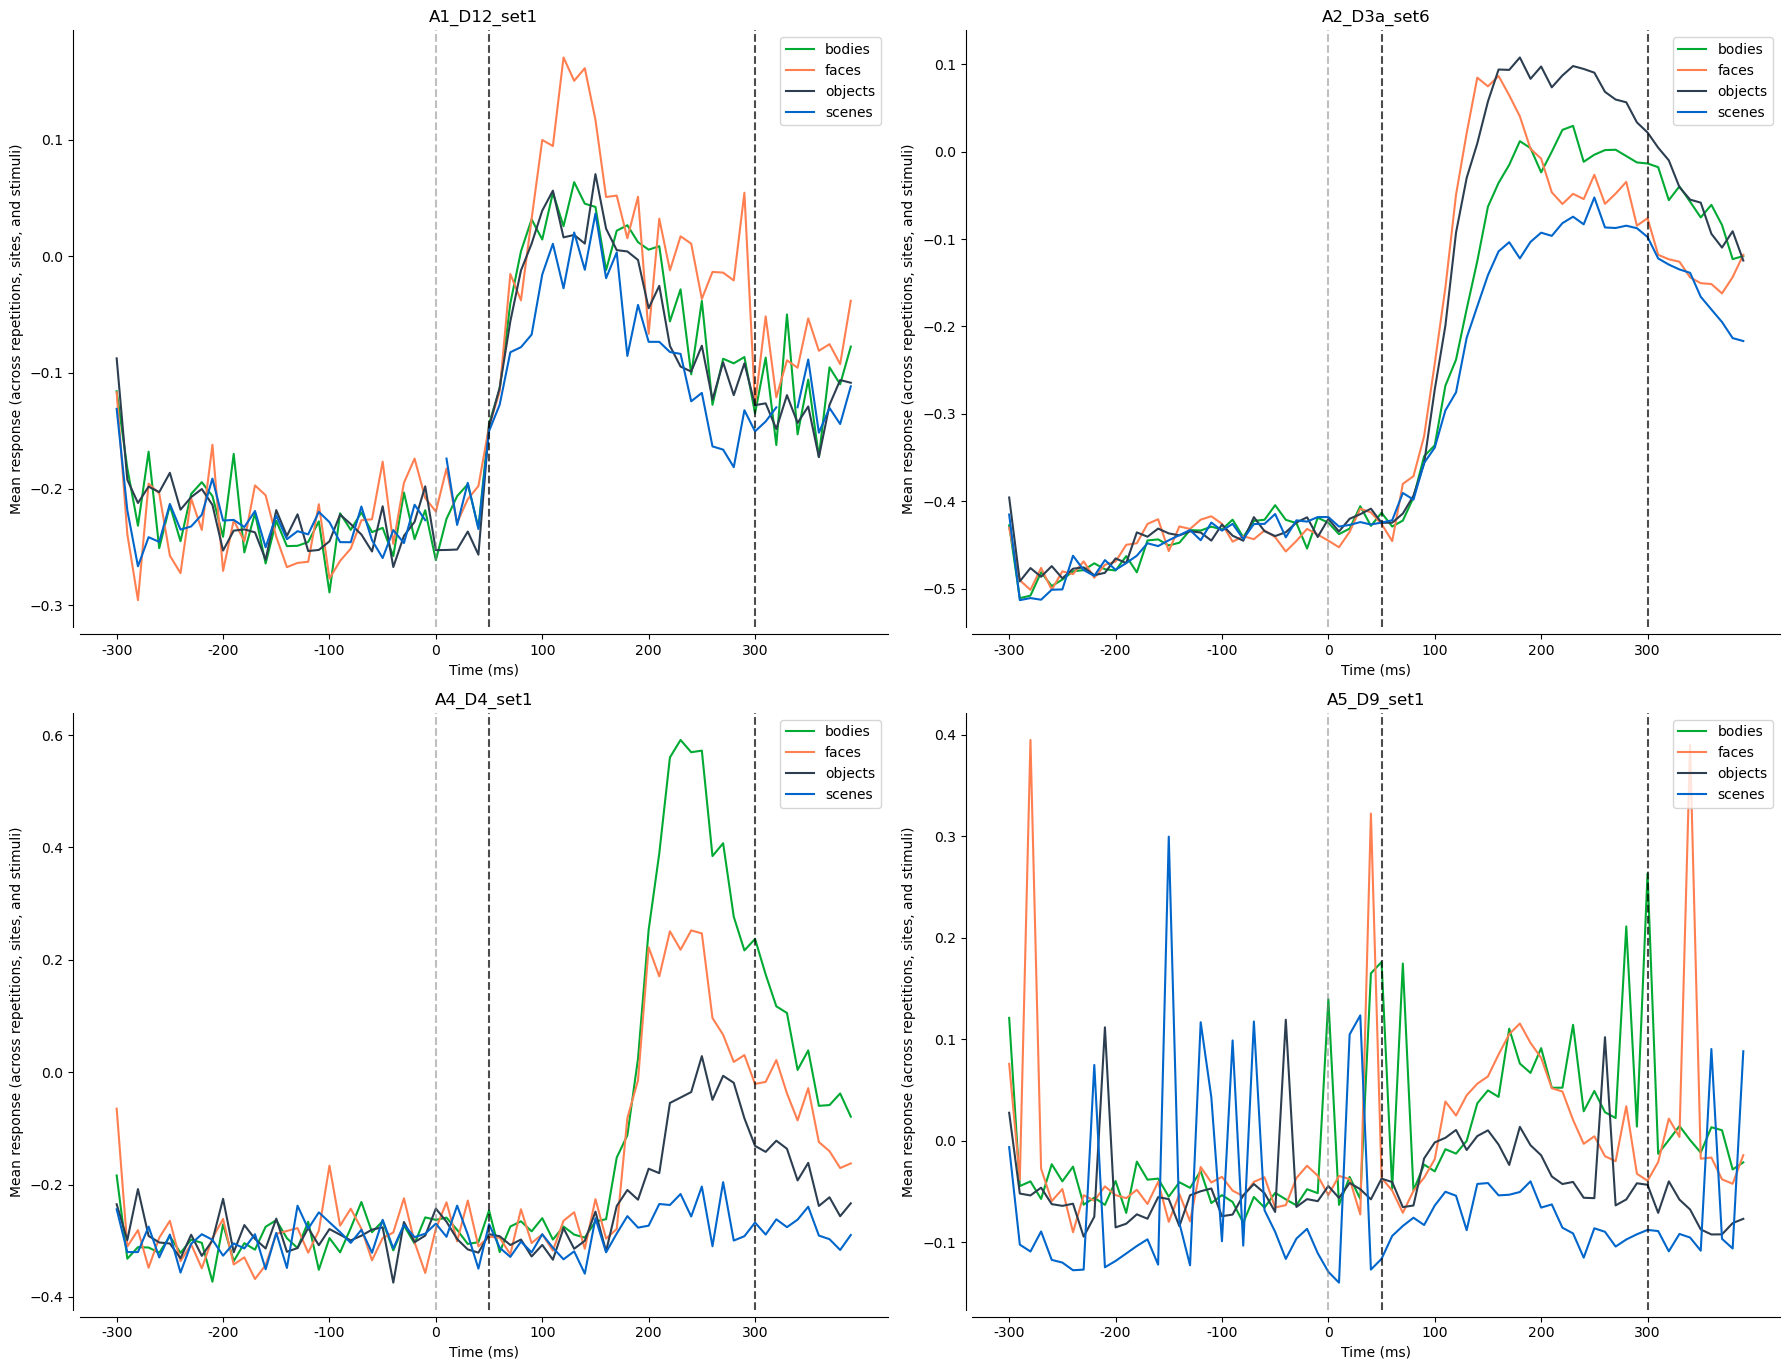

In [24]:
considered_data = ['A1_D12_set1', 'A2_D3a_set6', 'A4_D4_set1', 'A5_D9_set1']

image_info_df = pd.read_csv(f'{data_dir}/processed/image_info.csv')

# Add another column for original_image_idx, convert image1.bmp	-> 1 integer
image_info_df['original_image_idx'] = image_info_df['original_image_name'].str.extract(r'(\d+)').astype(int)

# Sort image_info_df based on original_image_name
image_info_df_sorted = image_info_df.sort_values(by='original_image_idx')

m185_labels = murty185.LABELS
labels_intervals_info = []
old_label = m185_labels[0]
old_idx = 0
for lbl_idx, lbl in enumerate(m185_labels):
    if lbl != old_label:
        labels_intervals_info.append((old_label, old_idx+(lbl_idx-old_idx)/2, lbl_idx))
        old_label = lbl
        old_idx = lbl_idx
labels_intervals_info.append((old_label, old_idx+(len(m185_labels)-old_idx)/2, len(m185_labels)))

fig, ax = plt.subplots(2, 2, figsize=(18, 15)) # Hardcoded for 4 arrays, can be made more general if needed
category_colors = {
    'faces': '#FF7F50',      # Coral orange
    'scenes': '#0066CC',     # Deep blue
    'bodies': '#00AA33',     # Vibrant green
    'objects': '#2C3E50',    # Dark slate
}
for aidx, key in enumerate(considered_data):
    value = Y[key]
    ax_current = ax.flatten()[aidx]  # Change this if you want to plot in different subplots
    print(f"Plotting {key} with {len(value)} channels")
    Y_array = [value_['data'] for value_ in value.values()]
    Y_array = torch.tensor(np.stack(Y_array))
    sitemean_data = torch.nanmean(torch.nanmean(Y_array, dim=2), axis=0)
    n_timebins = Y_array.shape[-1]
    # Take mean per time bin across all stimuli of the same category
    for category in np.unique(m185_labels):
        m185_labels_corrected = m185_labels.copy()
        if key == 'A1_D3_set1':
            # Remove label at index 154 (0-indexed) which corresponds to the missing image im156
            m185_labels_corrected = np.delete(m185_labels_corrected, 154)
        category_mask = (np.array(m185_labels_corrected) == category)
        category_data = sitemean_data[category_mask].mean(axis=0)
        ax_current.plot(category_data, '-', color=category_colors.get(category, 'black'), label=f'{category}')
    ax_current.axvline(x=30, color='gray', linestyle='--', alpha=0.5)
    ax_current.axvline(x=35, color='k', linestyle='--', alpha=0.7)
    ax_current.axvline(x=60, color='k', linestyle='--', alpha=0.7)
    xticks_all = list(range(n_timebins))
    xtick_labels = np.array([i*10 for i in xticks_all]) - 300
    xtick_idxs = [idx for idx, xtl in enumerate(xtick_labels) if xtl%100 == 0]
    ax_current.set_xticks(ticks=np.array(xticks_all)[xtick_idxs], labels=np.array(xtick_labels)[xtick_idxs])
    ax_current.legend()
    ax_current.spines['top'].set_visible(False)
    ax_current.spines['right'].set_visible(False)
    ax_current.spines['left'].set_position(('outward', 5))
    ax_current.spines['bottom'].set_position(('outward', 5))
    ax_current.set_xlabel('Time (ms)')
    ax_current.set_ylabel('Mean response (across repetitions, sites, and stimuli)')
    ax_current.set_title(f'{key}')
# plt.suptitle('Response timecourse by category (mean across all sites and stimuli)', fontsize=16)
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

Plotting A1_D12_set1 with 100 channels
Plotting A2_D3a_set1 with 147 channels
Plotting A4_D4_set1 with 155 channels
Plotting A5_D9_set1 with 112 channels


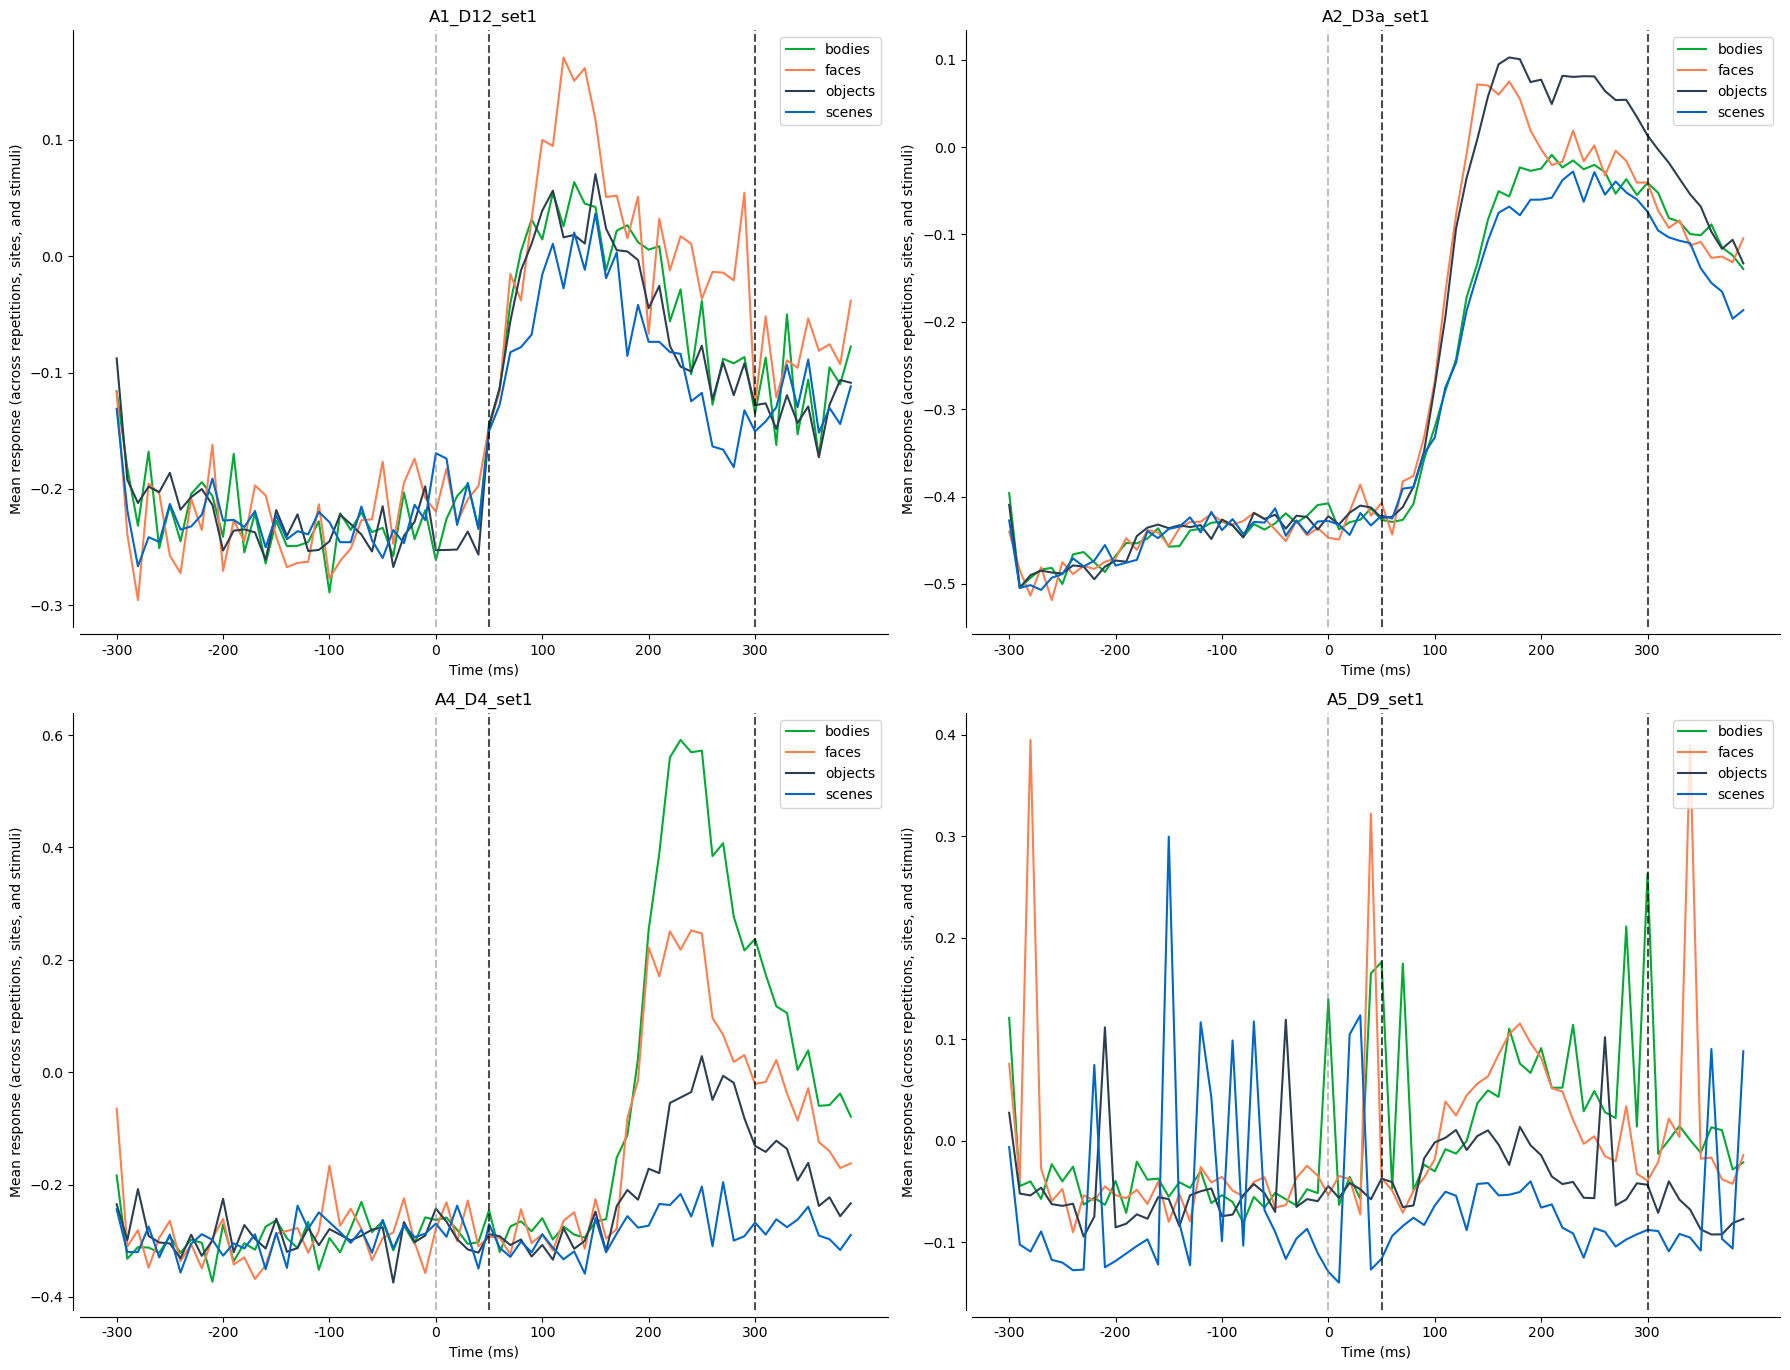

In [20]:
considered_data = ['A1_D12_set1', 'A2_D3a_set1', 'A4_D4_set1', 'A5_D9_set1']

image_info_df = pd.read_csv(f'{data_dir}/processed/image_info.csv')

# Add another column for original_image_idx, convert image1.bmp	-> 1 integer
image_info_df['original_image_idx'] = image_info_df['original_image_name'].str.extract(r'(\d+)').astype(int)

# Sort image_info_df based on original_image_name
image_info_df_sorted = image_info_df.sort_values(by='original_image_idx')

m185_labels = murty185.LABELS
labels_intervals_info = []
old_label = m185_labels[0]
old_idx = 0
for lbl_idx, lbl in enumerate(m185_labels):
    if lbl != old_label:
        labels_intervals_info.append((old_label, old_idx+(lbl_idx-old_idx)/2, lbl_idx))
        old_label = lbl
        old_idx = lbl_idx
labels_intervals_info.append((old_label, old_idx+(len(m185_labels)-old_idx)/2, len(m185_labels)))

fig, ax = plt.subplots(2, 2, figsize=(18, 15)) # Hardcoded for 4 arrays, can be made more general if needed
category_colors = {
    'faces': '#FF7F50',      # Coral orange
    'scenes': '#0066CC',     # Deep blue
    'bodies': '#00AA33',     # Vibrant green
    'objects': '#2C3E50',    # Dark slate
}
for aidx, key in enumerate(considered_data):
    ax_current = ax.flatten()[aidx]  # Change this if you want to plot in different subplots
    print(f"Plotting {key} with {len(Y_arrays[key])} channels")
    Y_array = torch.tensor(Y_arrays[key])
    sitemean_data = torch.nanmean(torch.nanmean(Y_array, dim=2), axis=0)
    n_timebins = Y_array.shape[-1]
    # Take mean per time bin across all stimuli of the same category
    for category in np.unique(m185_labels):
        m185_labels_corrected = m185_labels.copy()
        if key == 'A1_D3_set1':
            # Remove label at index 154 (0-indexed) which corresponds to the missing image im156
            m185_labels_corrected = np.delete(m185_labels_corrected, 154)
        category_mask = (np.array(m185_labels_corrected) == category)
        category_data = sitemean_data[category_mask].mean(axis=0)
        ax_current.plot(category_data, '-', color=category_colors.get(category, 'black'), label=f'{category}')
    ax_current.axvline(x=30, color='gray', linestyle='--', alpha=0.5)
    ax_current.axvline(x=35, color='k', linestyle='--', alpha=0.7)
    ax_current.axvline(x=60, color='k', linestyle='--', alpha=0.7)
    xticks_all = list(range(n_timebins))
    xtick_labels = np.array([i*10 for i in xticks_all]) - 300
    xtick_idxs = [idx for idx, xtl in enumerate(xtick_labels) if xtl%100 == 0]
    ax_current.set_xticks(ticks=np.array(xticks_all)[xtick_idxs], labels=np.array(xtick_labels)[xtick_idxs])
    ax_current.legend()
    ax_current.spines['top'].set_visible(False)
    ax_current.spines['right'].set_visible(False)
    ax_current.spines['left'].set_position(('outward', 5))
    ax_current.spines['bottom'].set_position(('outward', 5))
    ax_current.set_xlabel('Time (ms)')
    ax_current.set_ylabel('Mean response (across repetitions, sites, and stimuli)')
    ax_current.set_title(f'{key}')
# plt.suptitle('Response timecourse by category (mean across all sites and stimuli)', fontsize=16)
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

# ANN - neuron correlations

In [93]:
def get_correlation_matrix(X, Y, device="mps"):
    X, Y = X.to(device), Y.to(device)
    X_norm = (X - X.mean(1, keepdim=True)) / (X.std(1, keepdim=True) + 1e-8)
    Y_norm = (Y - Y.mean(1, keepdim=True)) / (Y.std(1, keepdim=True) + 1e-8)
    return torch.mm(X_norm, Y_norm.t()) / X.shape[1]

def bootstrap_ci(
    values,
    statistic="median",
    n_boot=1000,
    ci=95,
    seed=0
):
    """
    Compute bootstrap confidence interval for mean or median.

    Parameters
    ----------
    values : array-like
        1D array of values (e.g., model-level gaps).
    statistic : {"median", "mean"}
        Statistic to bootstrap.
    n_boot : int
        Number of bootstrap resamples.
    ci : float
        Confidence interval width (default 95).
    seed : int
        Random seed for reproducibility.

    Returns
    -------
    dict with:
        - stat (observed statistic)
        - ci_low
        - ci_high
    """
    values = np.asarray(values, dtype=float)
    values = values[~np.isnan(values)]
    rng = np.random.default_rng(seed)

    if statistic == "median":
        stat_fn = np.median
    elif statistic == "mean":
        stat_fn = np.mean
    else:
        raise ValueError("statistic must be 'median' or 'mean'")

    observed = stat_fn(values)

    boot_stats = []
    n = len(values)

    for _ in range(n_boot):
        sample = rng.choice(values, size=n, replace=True)
        boot_stats.append(stat_fn(sample))

    boot_stats = np.array(boot_stats)

    alpha = (100 - ci) / 2
    ci_low = np.percentile(boot_stats, alpha)
    ci_high = np.percentile(boot_stats, 100 - alpha)

    return {
        "stat": observed,
        "ci_low": ci_low,
        "ci_high": ci_high
    }

## One subplot per array

/var/folders/f4/jrx4_ljx4_q3d25kvtsnw4tw0000gq/T/ipykernel_59270/1644463328.py:24: RuntimeWarning: Mean of empty slice
  Y = torch.Tensor(np.nanmean(np.nanmean(neurons_data_binned, axis=-1), axis=-1))


Number of layers considered for the model resnet50openaiclip: 48


  0%|          | 0/48 [00:00<?, ?it/s]

Initialized resnet50random42 with seed = 42
Number of layers considered for the model resnet50random42: 48


  0%|          | 0/48 [00:00<?, ?it/s]

...

/var/folders/f4/jrx4_ljx4_q3d25kvtsnw4tw0000gq/T/ipykernel_59270/1644463328.py:24: RuntimeWarning: Mean of empty slice
  Y = torch.Tensor(np.nanmean(np.nanmean(neurons_data_binned, axis=-1), axis=-1))


Number of layers considered for the model resnet50openaiclip: 48


  0%|          | 0/48 [00:00<?, ?it/s]

Initialized resnet50random42 with seed = 42
Number of layers considered for the model resnet50random42: 48


  0%|          | 0/48 [00:00<?, ?it/s]

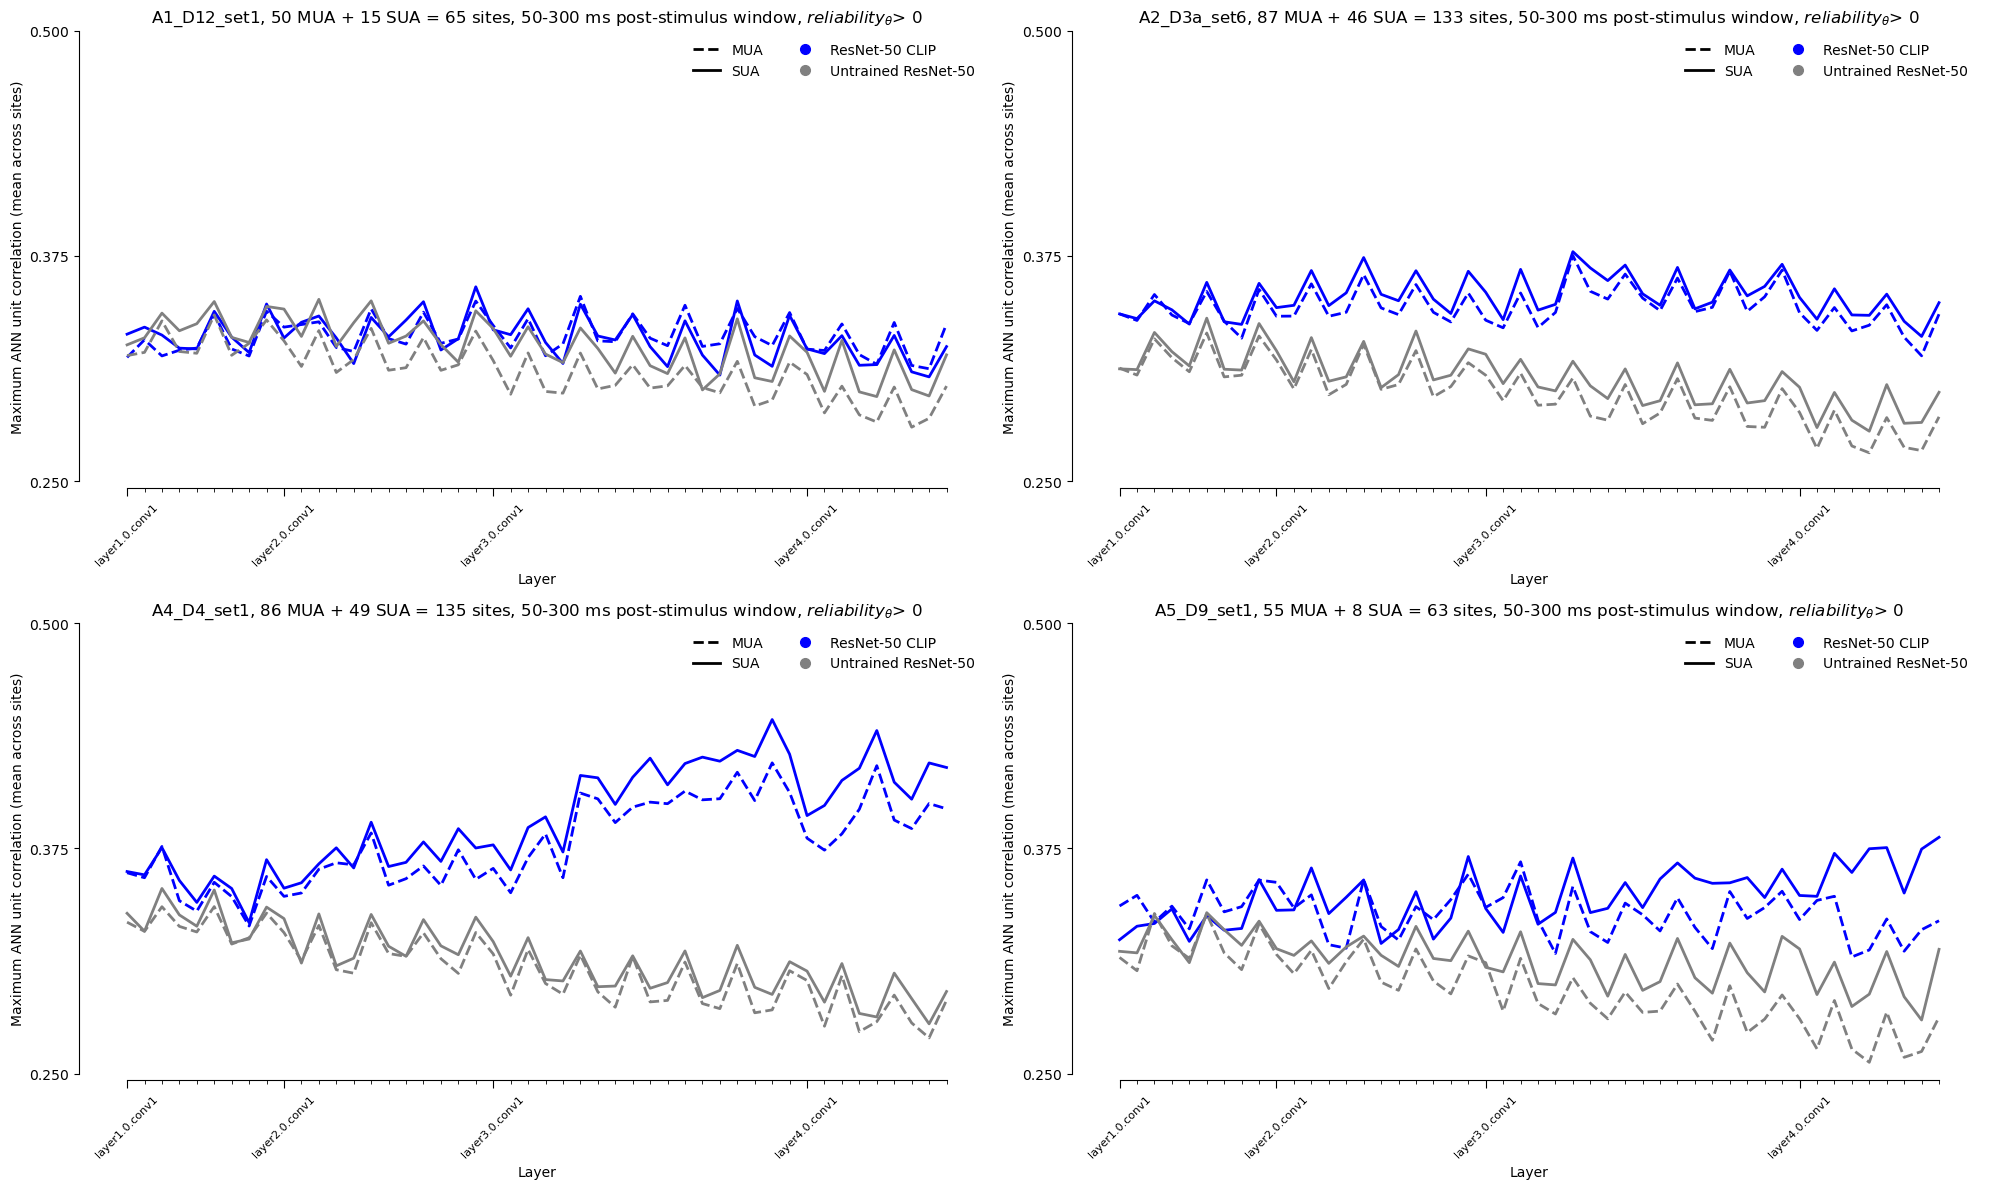

In [67]:
data_dir = '/Users/adipani3/datasets/intracranial'
assert os.path.exists(f'{data_dir}/processed')

considered_data = ['A1_D12_set1', 'A2_D3a_set6', 'A4_D4_set1', 'A5_D9_set1']
reliability_threshold = 0

fig, axs = plt.subplots(2, 2, figsize=(20, 12))
axs = axs.flatten()
colors_dict = {
    'MUA': 'blue',
    'SUA': 'red'
}

for kidx, key in enumerate(considered_data):
    ax = axs[kidx]
    neurons_data = np.load(f'{data_dir}/processed/NetSpikeRate_{key}_combined_10ms_Z_norm_per_channel_interval.npy')
    source_df = pd.read_csv(f'{data_dir}/processed/{key}_source_info.csv')

    # MUA/SUA labels
    source_labels = source_df['label'].values

    # Consider narrow response window (50-300ms post stimulus onset)
    neurons_data_binned = neurons_data[..., 35: 60]
    Y = torch.Tensor(np.nanmean(np.nanmean(neurons_data_binned, axis=-1), axis=-1))

    # Relaibilties
    relaibilities = relaibilities_binned[key]
    relaibilities = torch.Tensor(relaibilities)
    relaibility_mask = relaibilities > reliability_threshold

    # Mask according to reliability
    relaibilities = relaibilities[relaibility_mask]
    source_labels = source_labels[relaibility_mask]
    Y = Y[relaibility_mask, :]

    model = resnet50_openaiclip.get_model()
    model_all_relevant_layers = model.relevant_layer_names
    model_considered_layers = [layer for layer in model_all_relevant_layers if 'conv' in layer]
    print(f'Number of layers considered for the model {model.name}: {len(model_considered_layers)}')
    model_murty185_activations = model_utils.get_dataset_activations(
        MODELS_DIR,
        paths.MURTY185_DIR,
        model,
        model_considered_layers,
        'murty185',
    )
    model_murty185_activations = {k: v.flatten(start_dim=1).T for k, v in model_murty185_activations.items()}

    layer_correlation_matrices = {}
    layer_max_corrs = []
    for layer_name, layer_acts in tqdm(model_murty185_activations.items()):
        X = model_murty185_activations[layer_name]
        # print(f"Example shapes - X: {X_example}, Y: {Y.shape}")
        XY_corr_matrix = get_correlation_matrix(X, Y)
        # print(f"Correlation matrix shape: {XY_corr_matrix.shape}")
        layer_correlation_matrices[layer_name] = XY_corr_matrix
        XY_maxcorr, XY_maxcorr_idxs = XY_corr_matrix.max(dim=0)
        XY_maxcorr = XY_maxcorr.cpu() # /relaibilities
        layer_max_corrs.append(XY_maxcorr)

    layer_max_corrs = torch.stack(layer_max_corrs).T


    # Baseline model (untrained ResNet-50)
    baseline_model = resnet50_random.get_model()
    baseline_model_all_relevant_layers = baseline_model.relevant_layer_names
    baseline_model_considered_layers = [layer for layer in baseline_model_all_relevant_layers if 'conv' in layer]
    print(
        f'Number of layers considered for the model {baseline_model.name}: '
        f'{len(baseline_model_considered_layers)}'
    )
    baseline_model_murty185_activations = model_utils.get_dataset_activations(
        MODELS_DIR,
        paths.MURTY185_DIR,
        baseline_model,
        baseline_model_considered_layers,
        'murty185',
    )
    baseline_model_murty185_activations = {
        k: v.flatten(start_dim=1).T for k, v in baseline_model_murty185_activations.items()
    }
    baseline_layer_correlation_matrices = {}
    baseline_layer_max_corrs = []
    for layer_name, layer_acts in tqdm(baseline_model_murty185_activations.items()):
        baseline_X = baseline_model_murty185_activations[layer_name]
        baseline_XY_corr_matrix = get_correlation_matrix(baseline_X, Y)
        baseline_layer_correlation_matrices[layer_name] = baseline_XY_corr_matrix
        baseline_XY_maxcorr, baseline_XY_maxcorr_idxs = baseline_XY_corr_matrix.max(dim=0)
        baseline_XY_maxcorr = baseline_XY_maxcorr.cpu() #/relaibilities
        baseline_layer_max_corrs.append(baseline_XY_maxcorr)
    baseline_layer_max_corrs = torch.stack(baseline_layer_max_corrs).T

    # Plot correlation on y-axis and layer_idx on x-axis. different lines for each site, and color MUA/SUA with different colors
    layer_names = model_considered_layers
    mask_MUA = [label == 'MUA' for label in source_labels]
    mask_SUA = [label == 'SUA' for label in source_labels]
    n_sites, n_layers = layer_max_corrs.shape
    # Individual sites
    # for i in range(n_sites):
    #     max_corr = layer_max_corrs[i]
    #     label = source_labels[i]
    #     ax.plot(max_corr.cpu().numpy(), '-', color=colors_dict.get(label, 'black'), alpha=0.1)
    # Plot thick mean across all MUAs and SUAs
    # CLIP (blue)
    ax.plot(layer_max_corrs[mask_MUA].mean(axis=0).cpu().numpy(), '--', color='blue', linewidth=2)
    ax.plot(layer_max_corrs[mask_SUA].mean(axis=0).cpu().numpy(), '-', color='blue', linewidth=2)

    # Untrained baseline (gray)
    ax.plot(baseline_layer_max_corrs[mask_MUA].mean(axis=0).cpu().numpy(), '--', color='gray', linewidth=2)
    ax.plot(baseline_layer_max_corrs[mask_SUA].mean(axis=0).cpu().numpy(), '-', color='gray', linewidth=2)

    # Custom legend: line style = unit type, dot color = model
    custom_handles = [
        plt.Line2D([0], [0], color='black', linestyle='--', linewidth=2, label='MUA'),
        plt.Line2D([0], [0], color='black', linestyle='-', linewidth=2, label='SUA'),
        plt.Line2D([0], [0], marker='o', color='blue', linestyle='None', markersize=7, label='ResNet-50 CLIP'),
        plt.Line2D([0], [0], marker='o', color='gray', linestyle='None', markersize=7, label='Untrained ResNet-50'),
    ]
    ax.legend(handles=custom_handles, frameon=False, ncol=2)
    ax.set_ylim(0, 1)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_position(('outward', 5))
    ax.spines['bottom'].set_position(('outward', 5))
    ax.set_yticks([0.25, 0.375, 0.5])
    ax.spines['left'].set_bounds(0.25, 0.5)
    # ax.set_ylim(0.45, 1)
    ax.set_ylim(0.25, 0.5)
    ax.spines['bottom'].set_bounds(0, n_layers-1)
    # Plot xticks only if layer_name has conv1 in it
    major_tick_positions = [i for i, name in enumerate(layer_names) if '0.conv1' in name]
    minor_tick_positions = [i for i in range(n_layers) if i not in major_tick_positions]

    ax.set_xticks(major_tick_positions)
    ax.set_xticklabels([layer_names[i] for i in major_tick_positions], rotation=45, fontsize=8)

    ax.set_xticks(minor_tick_positions, minor=True)
    ax.tick_params(axis='x', which='major', length=6)
    ax.tick_params(axis='x', which='minor', length=3, labelbottom=False)
    ax.set_xlabel('Layer')
    ax.set_ylabel('Maximum ANN unit correlation (mean across sites)')
    # plt.ylabel('Noise-corrected maximum ANN unit correlation (mean across sites)')
    title_str = f'{key}, '
    unique_labels, counts = np.unique(source_labels, return_counts=True)
    for i, (unique_label, count) in enumerate(zip(unique_labels, counts)):
        title_str += f'{count} {unique_label}'
        if i == 0:
            title_str += ' + '
    title_str += f' = {np.sum(counts)} sites, 50-300 ms post-stimulus window, ' + r'$reliability_{\theta}$' + f'> {reliability_threshold}'
    ax.set_title(title_str)
plt.tight_layout()
plt.show()

## All arrays in one plot (MUAs & SUAs)

/var/folders/f4/jrx4_ljx4_q3d25kvtsnw4tw0000gq/T/ipykernel_59270/978572604.py:27: RuntimeWarning: Mean of empty slice
  Y = torch.Tensor(np.nanmean(np.nanmean(neurons_data_binned, axis=-1), axis=-1))


Number of layers considered for the model resnet50openaiclip: 48


  0%|          | 0/48 [00:00<?, ?it/s]

Initialized resnet50random42 with seed = 42
Number of layers considered for the model resnet50random42: 48


  0%|          | 0/48 [00:00<?, ?it/s]

...

/var/folders/f4/jrx4_ljx4_q3d25kvtsnw4tw0000gq/T/ipykernel_59270/978572604.py:27: RuntimeWarning: Mean of empty slice
  Y = torch.Tensor(np.nanmean(np.nanmean(neurons_data_binned, axis=-1), axis=-1))


Number of layers considered for the model resnet50openaiclip: 48


  0%|          | 0/48 [00:00<?, ?it/s]

Initialized resnet50random42 with seed = 42
Number of layers considered for the model resnet50random42: 48


  0%|          | 0/48 [00:00<?, ?it/s]

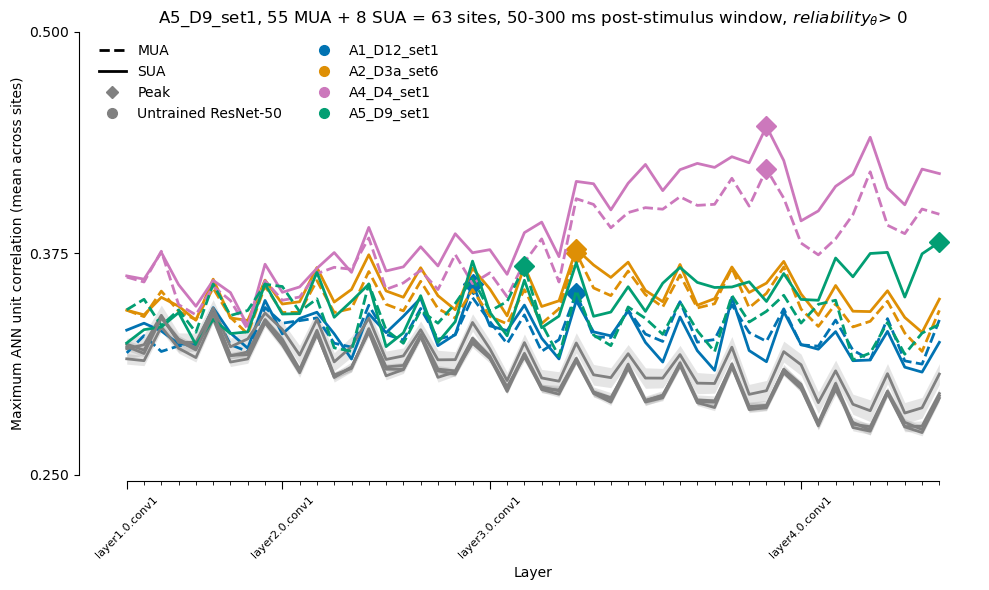

In [71]:
data_dir = '/Users/adipani3/datasets/intracranial'
assert os.path.exists(f'{data_dir}/processed')

considered_data = ['A1_D12_set1', 'A2_D3a_set6', 'A4_D4_set1', 'A5_D9_set1']
reliability_threshold = 0

fig, ax = plt.subplots(figsize=(10, 6))
axs = axs.flatten()
colors_dict = {
    'A1_D12_set1': '#0173B2',  # Blue
    'A2_D3a_set6': '#DE8F05',  # Orange
    'A4_D4_set1': '#CC78BC',   # Purple
    'A5_D9_set1': '#029E73',   # Green
}

baseline_layer_max_corrs_collated = None

for kidx, key in enumerate(considered_data):
    neurons_data = np.load(f'{data_dir}/processed/NetSpikeRate_{key}_combined_10ms_Z_norm_per_channel_interval.npy')
    source_df = pd.read_csv(f'{data_dir}/processed/{key}_source_info.csv')

    # MUA/SUA labels
    source_labels = source_df['label'].values

    # Consider narrow response window (50-300ms post stimulus onset)
    neurons_data_binned = neurons_data[..., 35: 60]
    Y = torch.Tensor(np.nanmean(np.nanmean(neurons_data_binned, axis=-1), axis=-1))

    # Relaibilties
    relaibilities = relaibilities_binned[key]
    relaibilities = torch.Tensor(relaibilities)
    relaibility_mask = relaibilities > reliability_threshold

    # Mask according to reliability
    relaibilities = relaibilities[relaibility_mask]
    source_labels = source_labels[relaibility_mask]
    Y = Y[relaibility_mask, :]

    model = resnet50_openaiclip.get_model()
    model_all_relevant_layers = model.relevant_layer_names
    model_considered_layers = [layer for layer in model_all_relevant_layers if 'conv' in layer]
    print(f'Number of layers considered for the model {model.name}: {len(model_considered_layers)}')
    model_murty185_activations = model_utils.get_dataset_activations(
        MODELS_DIR,
        paths.MURTY185_DIR,
        model,
        model_considered_layers,
        'murty185',
    )
    model_murty185_activations = {k: v.flatten(start_dim=1).T for k, v in model_murty185_activations.items()}

    layer_correlation_matrices = {}
    layer_max_corrs = []
    for layer_name, layer_acts in tqdm(model_murty185_activations.items()):
        X = model_murty185_activations[layer_name]
        # print(f"Example shapes - X: {X_example}, Y: {Y.shape}")
        XY_corr_matrix = get_correlation_matrix(X, Y)
        # print(f"Correlation matrix shape: {XY_corr_matrix.shape}")
        layer_correlation_matrices[layer_name] = XY_corr_matrix
        XY_maxcorr, XY_maxcorr_idxs = XY_corr_matrix.max(dim=0)
        XY_maxcorr = XY_maxcorr.cpu() # /relaibilities
        layer_max_corrs.append(XY_maxcorr)

    layer_max_corrs = torch.stack(layer_max_corrs).T


    # Baseline model (untrained ResNet-50)
    baseline_model = resnet50_random.get_model()
    baseline_model_all_relevant_layers = baseline_model.relevant_layer_names
    baseline_model_considered_layers = [layer for layer in baseline_model_all_relevant_layers if 'conv' in layer]
    print(
        f'Number of layers considered for the model {baseline_model.name}: '
        f'{len(baseline_model_considered_layers)}'
    )
    baseline_model_murty185_activations = model_utils.get_dataset_activations(
        MODELS_DIR,
        paths.MURTY185_DIR,
        baseline_model,
        baseline_model_considered_layers,
        'murty185',
    )
    baseline_model_murty185_activations = {
        k: v.flatten(start_dim=1).T for k, v in baseline_model_murty185_activations.items()
    }
    baseline_layer_correlation_matrices = {}
    baseline_layer_max_corrs = []
    for layer_name, layer_acts in tqdm(baseline_model_murty185_activations.items()):
        baseline_X = baseline_model_murty185_activations[layer_name]
        baseline_XY_corr_matrix = get_correlation_matrix(baseline_X, Y)
        baseline_layer_correlation_matrices[layer_name] = baseline_XY_corr_matrix
        baseline_XY_maxcorr, baseline_XY_maxcorr_idxs = baseline_XY_corr_matrix.max(dim=0)
        baseline_XY_maxcorr = baseline_XY_maxcorr.cpu() #/relaibilities
        baseline_layer_max_corrs.append(baseline_XY_maxcorr)
    baseline_layer_max_corrs = torch.stack(baseline_layer_max_corrs).T
    if baseline_layer_max_corrs_collated is None:
        baseline_layer_max_corrs_collated = baseline_layer_max_corrs
    else:
        baseline_layer_max_corrs_collated = torch.cat([baseline_layer_max_corrs_collated, baseline_layer_max_corrs], dim=0)

    # Plot correlation on y-axis and layer_idx on x-axis. different lines for each site, and color MUA/SUA with different colors
    layer_names = model_considered_layers
    mask_MUA = [label == 'MUA' for label in source_labels]
    mask_SUA = [label == 'SUA' for label in source_labels]
    n_sites, n_layers = layer_max_corrs.shape
    # Individual sites
    # for i in range(n_sites):
    #     max_corr = layer_max_corrs[i]
    #     label = source_labels[i]
    #     ax.plot(max_corr.cpu().numpy(), '-', color=colors_dict.get(label, 'black'), alpha=0.1)
    # Plot thick mean across all MUAs and SUAs
    # CLIP (blue)
    x_layers = np.arange(n_layers)
    mask_MUA = np.asarray(mask_MUA)
    mask_SUA = np.asarray(mask_SUA)

    if mask_MUA.any():
        mua_mean = layer_max_corrs[mask_MUA].mean(dim=0).cpu().numpy()
        ax.plot(x_layers, mua_mean, '--', color=colors_dict[key], linewidth=2)
        mua_peak_idx = int(np.argmax(mua_mean))
        ax.plot(
            x_layers[mua_peak_idx],
            mua_mean[mua_peak_idx],
            marker='D',
            color=colors_dict[key],
            markersize=10,
            linestyle='None',
        )

    if mask_SUA.any():
        sua_mean = layer_max_corrs[mask_SUA].mean(dim=0).cpu().numpy()
        ax.plot(x_layers, sua_mean, '-', color=colors_dict[key], linewidth=2)
        sua_peak_idx = int(np.argmax(sua_mean))
        ax.plot(
            x_layers[sua_peak_idx],
            sua_mean[sua_peak_idx],
            marker='D',
            color=colors_dict[key],
            markersize=10,
            linestyle='None',
        )

    # Untrained baseline (gray)
    x = np.arange(n_layers)
    baseline_mean = baseline_layer_max_corrs_collated.mean(dim=0).cpu().numpy()
    baseline_sem = (
        baseline_layer_max_corrs_collated.std(dim=0, unbiased=False).cpu().numpy()
        / np.sqrt(baseline_layer_max_corrs_collated.shape[0])
    )

    ax.plot(x, baseline_mean, '-', color='gray', linewidth=2)
    ax.fill_between(
        x,
        baseline_mean - baseline_sem,
        baseline_mean + baseline_sem,
        color='gray',
        alpha=0.2,
        linewidth=0,
    )

# Custom legend: line style = unit type, dot color = model
custom_handles = [
    plt.Line2D([0], [0], color='black', linestyle='--', linewidth=2, label='MUA'),
    plt.Line2D([0], [0], color='black', linestyle='-', linewidth=2, label='SUA'),
]

# Add diamond marker for peak
custom_handles.append(
    plt.Line2D(
        [0], [0],
        marker='D',
        color='gray',
        linestyle='None',
        markersize=6,
        label='Peak'
    )
)
# Baseline handle
custom_handles.append(
    plt.Line2D(
        [0], [0],
        marker='o',
        color='gray',
        linestyle='None',
        markersize=7,
        label='Untrained ResNet-50'
    )
)

# One handle per array/site in considered_data (using colors_dict)
for array_name in considered_data:
    custom_handles.append(
        plt.Line2D(
            [0], [0],
            marker='o',
            color=colors_dict.get(array_name, 'black'),
            linestyle='None',
            markersize=7,
            label=array_name
        )
    )

ax.legend(handles=custom_handles, frameon=False, ncol=2)
ax.set_ylim(0, 1)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_position(('outward', 5))
ax.spines['bottom'].set_position(('outward', 5))
ax.set_yticks([0.25, 0.375, 0.5])
ax.spines['left'].set_bounds(0.25, 0.5)
# ax.set_ylim(0.45, 1)
ax.set_ylim(0.25, 0.5)
ax.spines['bottom'].set_bounds(0, n_layers-1)
# Plot xticks only if layer_name has conv1 in it
major_tick_positions = [i for i, name in enumerate(layer_names) if '0.conv1' in name]
minor_tick_positions = [i for i in range(n_layers) if i not in major_tick_positions]

ax.set_xticks(major_tick_positions)
ax.set_xticklabels([layer_names[i] for i in major_tick_positions], rotation=45, fontsize=8)

ax.set_xticks(minor_tick_positions, minor=True)
ax.tick_params(axis='x', which='major', length=6)
ax.tick_params(axis='x', which='minor', length=3, labelbottom=False)
ax.set_xlabel('Layer')
ax.set_ylabel('Maximum ANN unit correlation (mean across sites)')
# plt.ylabel('Noise-corrected maximum ANN unit correlation (mean across sites)')
title_str = f'{key}, '
unique_labels, counts = np.unique(source_labels, return_counts=True)
for i, (unique_label, count) in enumerate(zip(unique_labels, counts)):
    title_str += f'{count} {unique_label}'
    if i == 0:
        title_str += ' + '
title_str += f' = {np.sum(counts)} sites, 50-300 ms post-stimulus window, ' + r'$reliability_{\theta}$' + f'> {reliability_threshold}'
ax.set_title(title_str)
plt.tight_layout()
plt.show()

## All arrays in one plot (mean across MUAs & SUAs)

/var/folders/f4/jrx4_ljx4_q3d25kvtsnw4tw0000gq/T/ipykernel_59270/3450986587.py:24: RuntimeWarning: Mean of empty slice
  Y = torch.Tensor(np.nanmean(np.nanmean(neurons_data_binned, axis=-1), axis=-1))


Number of layers considered for the model resnet50openaiclip: 48


  0%|          | 0/48 [00:00<?, ?it/s]

Initialized resnet50random42 with seed = 42
Number of layers considered for the model resnet50random42: 48


  0%|          | 0/48 [00:00<?, ?it/s]

...

/var/folders/f4/jrx4_ljx4_q3d25kvtsnw4tw0000gq/T/ipykernel_59270/3450986587.py:24: RuntimeWarning: Mean of empty slice
  Y = torch.Tensor(np.nanmean(np.nanmean(neurons_data_binned, axis=-1), axis=-1))


Number of layers considered for the model resnet50openaiclip: 48


  0%|          | 0/48 [00:00<?, ?it/s]

Initialized resnet50random42 with seed = 42
Number of layers considered for the model resnet50random42: 48


  0%|          | 0/48 [00:00<?, ?it/s]

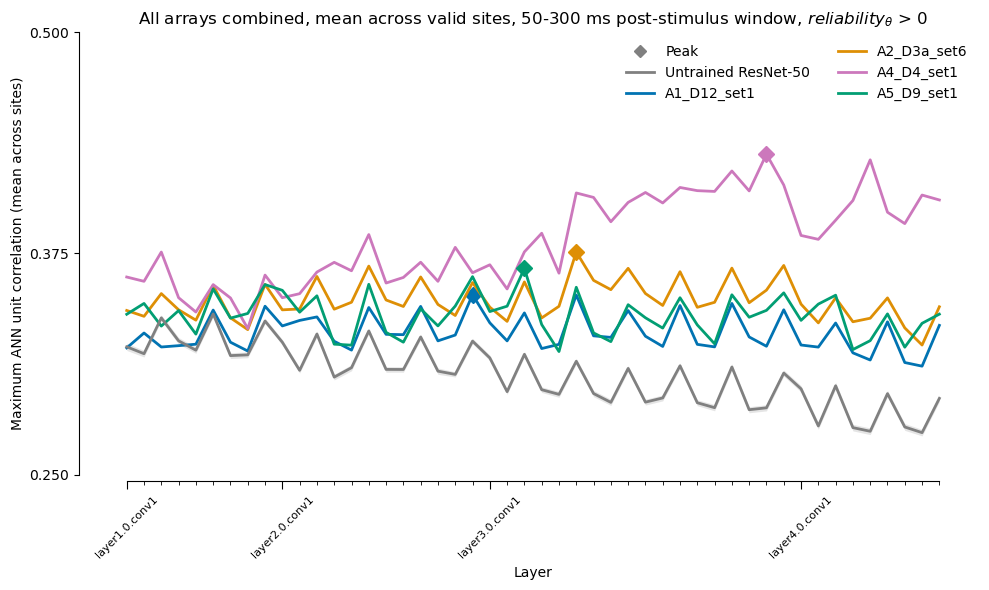

In [ ]:
data_dir = '/Users/adipani3/datasets/intracranial'
assert os.path.exists(f'{data_dir}/processed')

considered_data = ['A1_D12_set1', 'A2_D3a_set6', 'A4_D4_set1', 'A5_D9_set1']
reliability_threshold = 0

fig, ax = plt.subplots(figsize=(10, 6))
colors_dict = {
    'A1_D12_set1': '#0173B2',  # Blue
    'A2_D3a_set6': '#DE8F05',  # Orange
    'A4_D4_set1': '#CC78BC',   # Purple
    'A5_D9_set1': '#029E73',   # Green
}

baseline_layer_max_corrs_collated = None

for kidx, key in enumerate(considered_data):
    neurons_data = np.load(f'{data_dir}/processed/NetSpikeRate_{key}_combined_10ms_Z_norm_per_channel_interval.npy')
    source_df = pd.read_csv(f'{data_dir}/processed/{key}_source_info.csv')

    source_labels = source_df['label'].values

    neurons_data_binned = neurons_data[..., 35:60]
    Y = torch.Tensor(np.nanmean(np.nanmean(neurons_data_binned, axis=-1), axis=-1))

    relaibilities = torch.Tensor(relaibilities_binned[key])
    relaibility_mask = relaibilities > reliability_threshold

    relaibilities = relaibilities[relaibility_mask]
    source_labels = source_labels[relaibility_mask]
    Y = Y[relaibility_mask, :]

    model = resnet50_openaiclip.get_model()
    model_all_relevant_layers = model.relevant_layer_names
    model_considered_layers = [layer for layer in model_all_relevant_layers if 'conv' in layer]
    print(f'Number of layers considered for the model {model.name}: {len(model_considered_layers)}')

    model_murty185_activations = model_utils.get_dataset_activations(
        MODELS_DIR,
        paths.MURTY185_DIR,
        model,
        model_considered_layers,
        'murty185',
    )
    model_murty185_activations = {k: v.flatten(start_dim=1).T for k, v in model_murty185_activations.items()}

    layer_max_corrs = []
    for layer_name, layer_acts in tqdm(model_murty185_activations.items()):
        X = model_murty185_activations[layer_name]
        XY_corr_matrix = get_correlation_matrix(X, Y)
        XY_maxcorr, _ = XY_corr_matrix.max(dim=0)
        layer_max_corrs.append(XY_maxcorr.cpu())

    layer_max_corrs = torch.stack(layer_max_corrs).T  # [n_sites, n_layers]

    baseline_model = resnet50_random.get_model()
    baseline_model_all_relevant_layers = baseline_model.relevant_layer_names
    baseline_model_considered_layers = [layer for layer in baseline_model_all_relevant_layers if 'conv' in layer]
    print(
        f'Number of layers considered for the model {baseline_model.name}: '
        f'{len(baseline_model_considered_layers)}'
    )

    baseline_model_murty185_activations = model_utils.get_dataset_activations(
        MODELS_DIR,
        paths.MURTY185_DIR,
        baseline_model,
        baseline_model_considered_layers,
        'murty185',
    )
    baseline_model_murty185_activations = {
        k: v.flatten(start_dim=1).T for k, v in baseline_model_murty185_activations.items()
    }

    baseline_layer_max_corrs = []
    for layer_name, layer_acts in tqdm(baseline_model_murty185_activations.items()):
        baseline_X = baseline_model_murty185_activations[layer_name]
        baseline_XY_corr_matrix = get_correlation_matrix(baseline_X, Y)
        baseline_XY_maxcorr, _ = baseline_XY_corr_matrix.max(dim=0)
        baseline_layer_max_corrs.append(baseline_XY_maxcorr.cpu())

    baseline_layer_max_corrs = torch.stack(baseline_layer_max_corrs).T

    if baseline_layer_max_corrs_collated is None:
        baseline_layer_max_corrs_collated = baseline_layer_max_corrs
    else:
        baseline_layer_max_corrs_collated = torch.cat(
            [baseline_layer_max_corrs_collated, baseline_layer_max_corrs], dim=0
        )

    layer_names = model_considered_layers
    n_sites, n_layers = layer_max_corrs.shape
    x_layers = np.arange(n_layers)

    # Mean across all valid sites (no MUA/SUA split)
    overall_mean = layer_max_corrs.mean(dim=0).cpu().numpy()
    ax.plot(x_layers, overall_mean, '-', color=colors_dict[key], linewidth=2)
    peak_idx = int(np.argmax(overall_mean))
    ax.plot(
        x_layers[peak_idx],
        overall_mean[peak_idx],
        marker='D',
        color=colors_dict[key],
        markersize=8,
        linestyle='None',
    )

# Untrained baseline across all collated sites
x = np.arange(n_layers)
baseline_mean = baseline_layer_max_corrs_collated.mean(dim=0).cpu().numpy()
baseline_sem = (
    baseline_layer_max_corrs_collated.std(dim=0, unbiased=False).cpu().numpy()
    / np.sqrt(baseline_layer_max_corrs_collated.shape[0])
)

ax.plot(x, baseline_mean, '-', color='gray', linewidth=2, label='Untrained ResNet-50')
ax.fill_between(
    x,
    baseline_mean - baseline_sem,
    baseline_mean + baseline_sem,
    color='gray',
    alpha=0.2,
    linewidth=0,
)

# Legend
custom_handles = [
    plt.Line2D([0], [0], marker='D', color='gray', linestyle='None', markersize=6, label='Peak'),
    plt.Line2D([0], [0], color='gray', linestyle='-', linewidth=2, label='Untrained ResNet-50'),
]
for array_name in considered_data:
    custom_handles.append(
        plt.Line2D(
            [0], [0],
            color=colors_dict.get(array_name, 'black'),
            linestyle='-',
            linewidth=2,
            label=array_name
        )
    )

ax.legend(handles=custom_handles, frameon=False, ncol=2)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_position(('outward', 5))
ax.spines['bottom'].set_position(('outward', 5))
ax.set_yticks([0.25, 0.375, 0.5])
ax.spines['left'].set_bounds(0.25, 0.5)
ax.set_ylim(0.25, 0.5)
ax.spines['bottom'].set_bounds(0, n_layers - 1)

major_tick_positions = [i for i, name in enumerate(layer_names) if '0.conv1' in name]
minor_tick_positions = [i for i in range(n_layers) if i not in major_tick_positions]

ax.set_xticks(major_tick_positions)
ax.set_xticklabels([layer_names[i] for i in major_tick_positions], rotation=45, fontsize=8)
ax.set_xticks(minor_tick_positions, minor=True)
ax.tick_params(axis='x', which='major', length=6)
ax.tick_params(axis='x', which='minor', length=3, labelbottom=False)

ax.set_xlabel('Layer')
ax.set_ylabel('Maximum ANN unit correlation (mean across sites)')
ax.set_title(
    f'All arrays combined, mean across valid sites, 50-300 ms post-stimulus window, '
    + r'$reliability_{\theta}$'
    + f' > {reliability_threshold}'
)
plt.tight_layout()
plt.show()


## Peak depth for all sites

In [53]:
data_dir = '/Users/adipani3/datasets/intracranial'
assert os.path.exists(f'{data_dir}/processed')

considered_data = ['A1_D12_set1', 'A2_D3a_set6', 'A4_D4_set1', 'A5_D9_set1']
reliability_threshold = 0

array_correlations = {}

for kidx, key in enumerate(considered_data):
    array_correlations[key] = {}
    neurons_data = np.load(f'{data_dir}/processed/NetSpikeRate_{key}_combined_10ms_Z_norm_per_channel_interval.npy')
    source_df = pd.read_csv(f'{data_dir}/processed/{key}_source_info.csv')

    # MUA/SUA labels
    source_labels = source_df['label'].values

    # Consider narrow response window (50-300ms post stimulus onset)
    neurons_data_binned = neurons_data[..., 35: 60]
    Y = torch.Tensor(np.nanmean(np.nanmean(neurons_data_binned, axis=-1), axis=-1))

    # Relaibilties
    relaibilities = relaibilities_binned[key]
    relaibilities = torch.Tensor(relaibilities)
    relaibility_mask = relaibilities > reliability_threshold

    # Mask according to reliability
    relaibilities = relaibilities[relaibility_mask]
    source_labels = source_labels[relaibility_mask]
    Y = Y[relaibility_mask, :]
    array_correlations[key]['reliabilities'] = relaibilities
    array_correlations[key]['source_labels'] = source_labels

    model = resnet50_openaiclip.get_model()
    model_all_relevant_layers = model.relevant_layer_names
    model_considered_layers = [layer for layer in model_all_relevant_layers if 'conv' in layer]
    print(f'Number of layers considered for the model {model.name}: {len(model_considered_layers)}')
    model_murty185_activations = model_utils.get_dataset_activations(
        MODELS_DIR,
        paths.MURTY185_DIR,
        model,
        model_considered_layers,
        'murty185',
    )
    model_murty185_activations = {k: v.flatten(start_dim=1).T for k, v in model_murty185_activations.items()}

    layer_correlation_matrices = {}
    layer_max_corrs = []
    for layer_name, layer_acts in tqdm(model_murty185_activations.items()):
        X = model_murty185_activations[layer_name]
        # print(f"Example shapes - X: {X_example}, Y: {Y.shape}")
        XY_corr_matrix = get_correlation_matrix(X, Y)
        # print(f"Correlation matrix shape: {XY_corr_matrix.shape}")
        layer_correlation_matrices[layer_name] = XY_corr_matrix
        XY_maxcorr, XY_maxcorr_idxs = XY_corr_matrix.max(dim=0)
        XY_maxcorr = XY_maxcorr.cpu() # /relaibilities
        layer_max_corrs.append(XY_maxcorr)

    layer_max_corrs = torch.stack(layer_max_corrs).T
    array_correlations[key]['layer_max_corrs'] = layer_max_corrs

    # Baseline model (untrained ResNet-50)
    baseline_model = resnet50_random.get_model()
    baseline_model_all_relevant_layers = baseline_model.relevant_layer_names
    baseline_model_considered_layers = [layer for layer in baseline_model_all_relevant_layers if 'conv' in layer]
    print(
        f'Number of layers considered for the model {baseline_model.name}: '
        f'{len(baseline_model_considered_layers)}'
    )
    baseline_model_murty185_activations = model_utils.get_dataset_activations(
        MODELS_DIR,
        paths.MURTY185_DIR,
        baseline_model,
        baseline_model_considered_layers,
        'murty185',
    )
    baseline_model_murty185_activations = {
        k: v.flatten(start_dim=1).T for k, v in baseline_model_murty185_activations.items()
    }
    baseline_layer_correlation_matrices = {}
    baseline_layer_max_corrs = []
    for layer_name, layer_acts in tqdm(baseline_model_murty185_activations.items()):
        baseline_X = baseline_model_murty185_activations[layer_name]
        baseline_XY_corr_matrix = get_correlation_matrix(baseline_X, Y)
        baseline_layer_correlation_matrices[layer_name] = baseline_XY_corr_matrix
        baseline_XY_maxcorr, baseline_XY_maxcorr_idxs = baseline_XY_corr_matrix.max(dim=0)
        baseline_XY_maxcorr = baseline_XY_maxcorr.cpu() #/relaibilities
        baseline_layer_max_corrs.append(baseline_XY_maxcorr)
    baseline_layer_max_corrs = torch.stack(baseline_layer_max_corrs).T
    array_correlations[key]['baseline_layer_max_corrs'] = baseline_layer_max_corrs

/var/folders/f4/jrx4_ljx4_q3d25kvtsnw4tw0000gq/T/ipykernel_4851/3183125608.py:19: RuntimeWarning: Mean of empty slice
  Y = torch.Tensor(np.nanmean(np.nanmean(neurons_data_binned, axis=-1), axis=-1))


Number of layers considered for the model resnet50openaiclip: 48


  0%|          | 0/48 [00:00<?, ?it/s]

Initialized resnet50random42 with seed = 42
Number of layers considered for the model resnet50random42: 48


  0%|          | 0/48 [00:00<?, ?it/s]

...

/var/folders/f4/jrx4_ljx4_q3d25kvtsnw4tw0000gq/T/ipykernel_4851/3183125608.py:19: RuntimeWarning: Mean of empty slice
  Y = torch.Tensor(np.nanmean(np.nanmean(neurons_data_binned, axis=-1), axis=-1))


Number of layers considered for the model resnet50openaiclip: 48


  0%|          | 0/48 [00:00<?, ?it/s]

Initialized resnet50random42 with seed = 42
Number of layers considered for the model resnet50random42: 48


  0%|          | 0/48 [00:00<?, ?it/s]

In [66]:
for key in array_correlations.keys():
    print(key)
    for k, v in array_correlations[key].items():
        print(f'{k}: {v.shape}')
    print('\n')

A1_D12_set1
reliabilities: torch.Size([65])
source_labels: (65,)
layer_max_corrs: torch.Size([65, 48])
baseline_layer_max_corrs: torch.Size([65, 48])


A2_D3a_set6
reliabilities: torch.Size([133])
source_labels: (133,)
layer_max_corrs: torch.Size([133, 48])
baseline_layer_max_corrs: torch.Size([133, 48])


A4_D4_set1
reliabilities: torch.Size([135])
source_labels: (135,)
layer_max_corrs: torch.Size([135, 48])
baseline_layer_max_corrs: torch.Size([135, 48])


A5_D9_set1
reliabilities: torch.Size([63])
source_labels: (63,)
layer_max_corrs: torch.Size([63, 48])
baseline_layer_max_corrs: torch.Size([63, 48])




In [38]:
key

'A1_D12_set1'

In [64]:
layer_max_corrs.shape

torch.Size([65, 48])

In [60]:
baseline_max_corrs.shape

torch.Size([65, 48])

In [62]:
mask_MUA.shape

(65,)

In [69]:
baseline_layer_max_corrs

tensor([[0.2610, 0.2724, 0.3370,  ..., 0.2489, 0.2262, 0.2510],
        [0.3191, 0.2953, 0.3606,  ..., 0.2407, 0.2628, 0.2540],
        [0.3081, 0.3129, 0.3661,  ..., 0.2576, 0.2710, 0.2844],
        ...,
        [0.3405, 0.3502, 0.3541,  ..., 0.2613, 0.2392, 0.3119],
        [0.2711, 0.2983, 0.3527,  ..., 0.2772, 0.2518, 0.2851],
        [0.2766, 0.3055, 0.3087,  ..., 0.2811, 0.2654, 0.2793]])

In [65]:
key

'A1_D12_set1'

In [73]:
source_labels.shape

(65,)

baseline corrs shape: torch.Size([65, 48])
baseline corrs shape: torch.Size([65, 48])
mask_MUA shape: (65,)
baseline corrs shape: torch.Size([133, 48])
baseline corrs shape: torch.Size([133, 48])
mask_MUA shape: (133,)
baseline corrs shape: torch.Size([135, 48])
baseline corrs shape: torch.Size([135, 48])
mask_MUA shape: (135,)
baseline corrs shape: torch.Size([63, 48])
baseline corrs shape: torch.Size([63, 48])
mask_MUA shape: (63,)


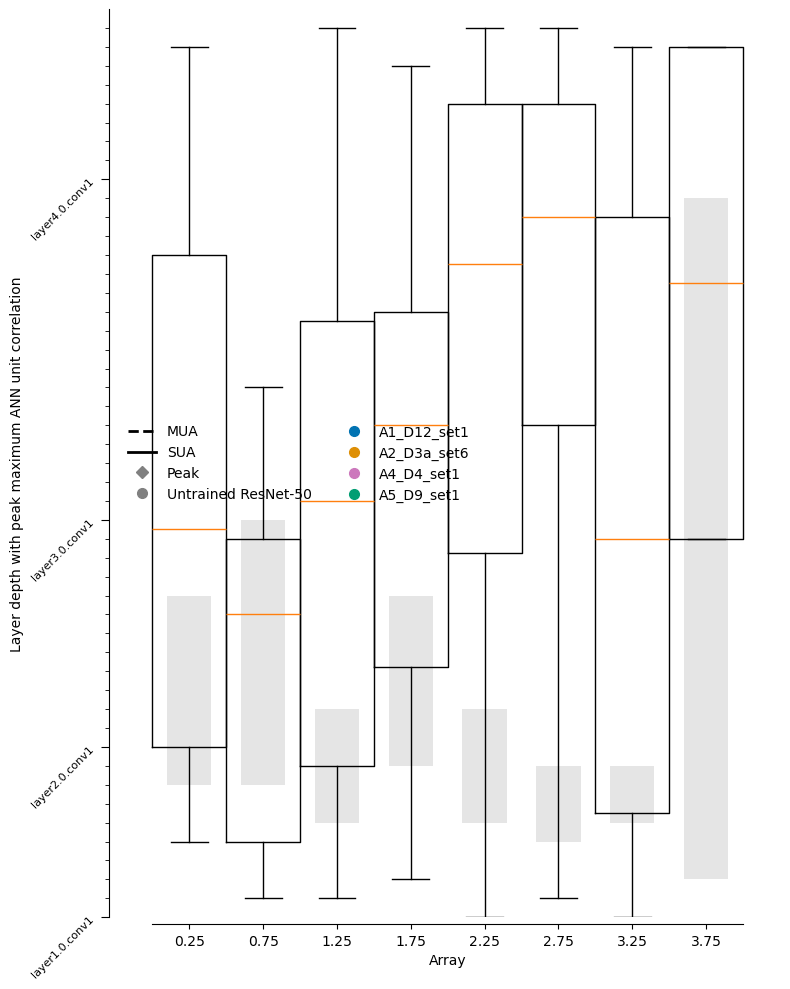

In [96]:
fig, ax = plt.subplots(figsize=(8, 10))
colors_dict = {
    'A1_D12_set1': '#0173B2',  # Blue
    'A2_D3a_set6': '#DE8F05',  # Orange
    'A4_D4_set1': '#CC78BC',   # Purple
    'A5_D9_set1': '#029E73',   # Green
    'MUA': 'blue', 
    'SUA': 'red'
}
layer_names = model_considered_layers

boxplot_data = []
box_xs = np.array([[0.25, 0.75], [1.25, 1.75], [2.25, 2.75], [3.25, 3.75]])
box_widths = 0.3
for kidx, key in enumerate(considered_data):
    layer_max_corrs = array_correlations[key]['layer_max_corrs']
    baseline_max_corrs = array_correlations[key]['baseline_layer_max_corrs']
    print(f'baseline corrs shape: {baseline_max_corrs.shape}')
    source_labels = array_correlations[key]['source_labels']

    # Plot correlation on y-axis and layer_idx on x-axis. different lines for each site, and color MUA/SUA with different colors
    mask_MUA = [label == 'MUA' for label in source_labels]
    mask_SUA = [label == 'SUA' for label in source_labels]
    n_sites, n_layers = layer_max_corrs.shape
    # Individual sites
    # for i in range(n_sites):
    #     max_corr = layer_max_corrs[i]
    #     label = source_labels[i]
    #     ax.plot(max_corr.cpu().numpy(), '-', color=colors_dict.get(label, 'black'), alpha=0.1)
    # Plot thick mean across all MUAs and SUAs
    # CLIP (blue)
    y_layers = np.arange(n_layers)
    mask_MUA = np.asarray(mask_MUA)
    mask_SUA = np.asarray(mask_SUA)

    if mask_MUA.any():
        mua_model_peaks = layer_max_corrs[mask_MUA].argmax(axis=-1).float()
        print(f'baseline corrs shape: {baseline_max_corrs.shape}')
        print(f'mask_MUA shape: {mask_MUA.shape}')
        mua_baseline_peaks = baseline_max_corrs[mask_MUA].argmax(axis=-1).float()
        # Plot a shaded area in gray for mean+-SEM of mua_baseline_peaks (at box_x[kidx] +- box_widths/2)
        mua_baseline_stats = bootstrap_ci(mua_baseline_peaks.cpu().numpy())
        ax.fill_between(
            [box_xs[kidx, 0] - box_widths/2, box_xs[kidx, 0] + box_widths/2],
            mua_baseline_stats['ci_low'],
            mua_baseline_stats['ci_high'],
            color='gray',
            alpha=0.2,
            linewidth=0,
        )
        boxplot_data.append(mua_model_peaks)

    if mask_SUA.any():
        sua_model_peaks = layer_max_corrs[mask_SUA].argmax(axis=-1).float()
        sua_baseline_peaks = baseline_max_corrs[mask_SUA].argmax(axis=-1).float()
        # Plot a shaded area in gray for mean+-SEM of sua_baseline_peaks (at box_x[kidx] +- box_widths/2)
        sua_baseline_stats = bootstrap_ci(sua_baseline_peaks.cpu().numpy())
        ax.fill_between(
            [box_xs[kidx, 1] - box_widths/2, box_xs[kidx, 1] + box_widths/2],
            sua_baseline_stats['ci_low'],
            sua_baseline_stats['ci_high'],
            color='gray',
            alpha=0.2,
            linewidth=0,
        )
        boxplot_data.append(sua_model_peaks)

# Plot the boxplot
ax.boxplot(
    boxplot_data, positions=box_xs.flatten(),
)

# Custom legend: line style = unit type, dot color = model
custom_handles = [
    plt.Line2D([0], [0], color='black', linestyle='--', linewidth=2, label='MUA'),
    plt.Line2D([0], [0], color='black', linestyle='-', linewidth=2, label='SUA'),
]

# Add diamond marker for peak
custom_handles.append(
    plt.Line2D(
        [0], [0],
        marker='D',
        color='gray',
        linestyle='None',
        markersize=6,
        label='Peak'
    )
)
# Baseline handle
custom_handles.append(
    plt.Line2D(
        [0], [0],
        marker='o',
        color='gray',
        linestyle='None',
        markersize=7,
        label='Untrained ResNet-50'
    )
)

# One handle per array/site in considered_data (using colors_dict)
for array_name in considered_data:
    custom_handles.append(
        plt.Line2D(
            [0], [0],
            marker='o',
            color=colors_dict.get(array_name, 'black'),
            linestyle='None',
            markersize=7,
            label=array_name
        )
    )

ax.legend(handles=custom_handles, frameon=False, ncol=2)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_position(('outward', 5))
ax.spines['bottom'].set_position(('outward', 5))
# Plot xticks only if layer_name has conv1 in it
major_tick_positions = [i for i, name in enumerate(layer_names) if '0.conv1' in name]
minor_tick_positions = [i for i in range(n_layers) if i not in major_tick_positions]
# ax.set_yticks([0.25, 0.375, 0.5])
# ax.spines['left'].set_bounds(0.25, 0.5)
ax.set_ylim(0, len(layer_names))
ax.set_yticks(major_tick_positions)
ax.set_yticklabels([layer_names[i] for i in major_tick_positions], rotation=45, fontsize=8)
ax.set_yticks(minor_tick_positions, minor=True)
ax.tick_params(axis='y', which='major', length=6)
ax.tick_params(axis='y', which='minor', length=3, labelbottom=False)

ax.spines['bottom'].set_bounds(0, len(considered_data))

ax.set_xlabel('Array')
ax.set_ylabel('Layer depth with peak maximum ANN unit correlation')
# plt.ylabel('Noise-corrected maximum ANN unit correlation (mean across sites)')
# title_str = f'{key}, '
# unique_labels, counts = np.unique(source_labels, return_counts=True)
# for i, (unique_label, count) in enumerate(zip(unique_labels, counts)):
#     title_str += f'{count} {unique_label}'
#     if i == 0:
#         title_str += ' + '
# title_str += f' = {np.sum(counts)} sites, 50-300 ms post-stimulus window, ' + r'$reliability_{\theta}$' + f'> {reliability_threshold}'
# ax.set_title(title_str)
plt.tight_layout()
plt.show()

In [84]:
print(f'baseline corrs shape: {baseline_max_corrs.shape}')
print(f'mask_MUA shape: {mask_MUA.shape}')

baseline corrs shape: torch.Size([65, 48])
mask_MUA shape: (65,)


In [85]:
baseline_layer_max_corrs[mask_SUA]

IndexError: The shape of the mask [65] at index 0 does not match the shape of the indexed tensor [63, 48] at index 0

In [86]:
mask_SUA

array([False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True])

In [81]:
baseline_layer_max_corrs.shape

torch.Size([63, 48])

In [80]:
baseline_layer_max_corrs.argmax(dim=-1).shape

torch.Size([63])

In [35]:
baseline_layer_max_corrs[mask_SUA]

IndexError: The shape of the mask [65] at index 0 does not match the shape of the indexed tensor [63, 48] at index 0

In [36]:
baseline_layer_max_corrs.shape

torch.Size([63, 48])

In [37]:
mask_SUA.shape

(65,)

## One array (A4)

In [ ]:
data_dir = '/Users/adipani3/datasets/intracranial/A4'
assert os.path.exists(f'{data_dir}/processed')
neurons_data = np.load(f'{data_dir}/processed/NetSpikeRate_Z_norm_per_channel_interval_processed.npy')
source_df = pd.read_csv(f'{data_dir}/processed/source_info.csv')
image_info_df = pd.read_csv(f'{data_dir}/processed/image_info.csv')

# MUA/SUA labels
source_labels = source_df['label'].values

# Consider narrow response window (200-300ms post stimulus onset)
neurons_data_binned = neurons_data[..., 50: 60]
Y = torch.Tensor(np.nanmean(np.nanmean(neurons_data_binned, axis=-1), axis=-1))

# Relaibilties
reliability_threshold = 0.3
relaibilities, _ = rel_utils.get_neuron_wise_splithalf_correlation(np.nanmean(neurons_data_binned, axis=-1))
relaibilities = torch.Tensor(relaibilities)
relaibility_mask = relaibilities > reliability_threshold

# Mask according to reliability
relaibilities = relaibilities[relaibility_mask]
source_labels = source_labels[relaibility_mask]
Y = Y[relaibility_mask, :]

Number of layers considered for the model resnet50openaiclip: 48


  0%|          | 0/48 [00:00<?, ?it/s]

Initialized resnet50random42 with seed = 42
Number of layers considered for the model resnet50random42: 48


  0%|          | 0/48 [00:00<?, ?it/s]

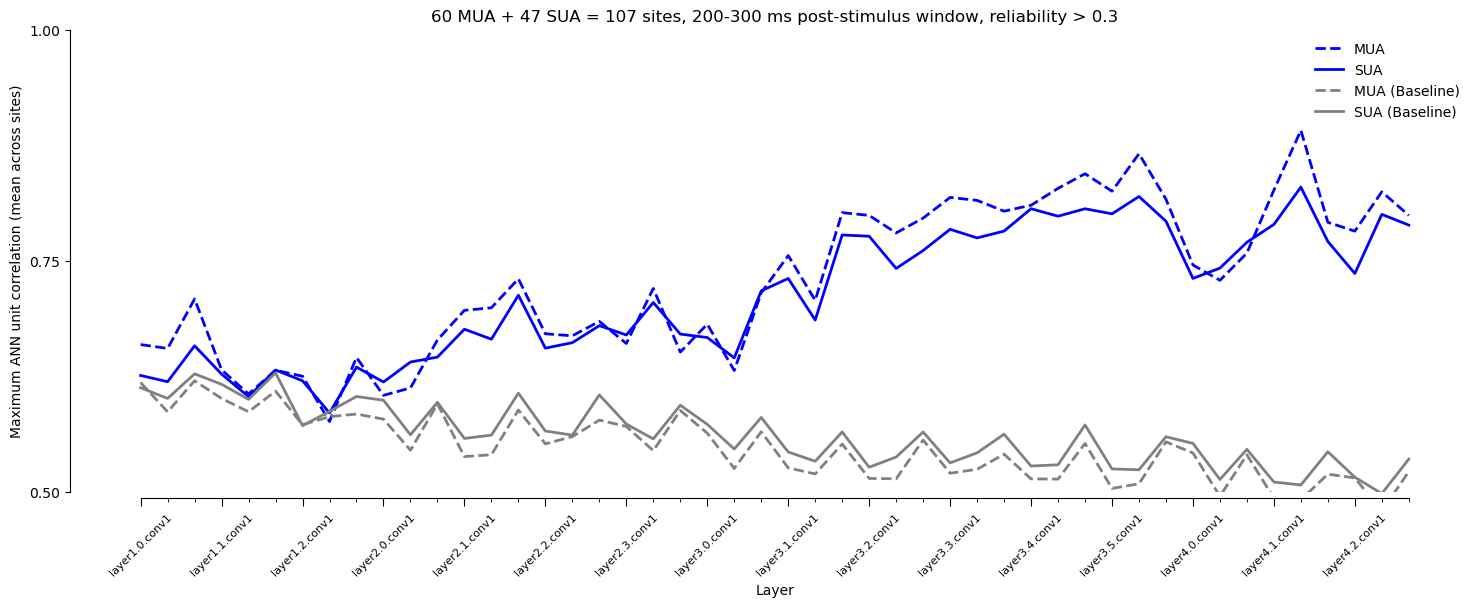

In [ ]:
model = resnet50_openaiclip.get_model()
model_all_relevant_layers = model.relevant_layer_names
model_considered_layers = [layer for layer in model_all_relevant_layers if 'conv' in layer]
print(f'Number of layers considered for the model {model.name}: {len(model_considered_layers)}')
model_murty185_activations = model_utils.get_dataset_activations(
    MODELS_DIR,
    paths.MURTY185_DIR,
    model,
    model_considered_layers,
    'murty185',
)
model_murty185_activations = {k: v.flatten(start_dim=1).T for k, v in model_murty185_activations.items()}

layer_correlation_matrices = {}
layer_max_corrs = []
for layer_name, layer_acts in tqdm(model_murty185_activations.items()):
    X = model_murty185_activations[layer_name]
    # print(f"Example shapes - X: {X_example}, Y: {Y.shape}")
    XY_corr_matrix = get_correlation_matrix(X, Y)
    # print(f"Correlation matrix shape: {XY_corr_matrix.shape}")
    layer_correlation_matrices[layer_name] = XY_corr_matrix
    XY_maxcorr, XY_maxcorr_idxs = XY_corr_matrix.max(dim=0)
    XY_maxcorr = XY_maxcorr.cpu()/relaibilities
    layer_max_corrs.append(XY_maxcorr)

layer_max_corrs = torch.stack(layer_max_corrs).T


# Baseline model (untrained ResNet-50)
baseline_model = resnet50_random.get_model()
baseline_model_all_relevant_layers = baseline_model.relevant_layer_names
baseline_model_considered_layers = [layer for layer in baseline_model_all_relevant_layers if 'conv' in layer]
print(
    f'Number of layers considered for the model {baseline_model.name}: '
    f'{len(baseline_model_considered_layers)}'
)
baseline_model_murty185_activations = model_utils.get_dataset_activations(
    MODELS_DIR,
    paths.MURTY185_DIR,
    baseline_model,
    baseline_model_considered_layers,
    'murty185',
)
baseline_model_murty185_activations = {
    k: v.flatten(start_dim=1).T for k, v in baseline_model_murty185_activations.items()
}
baseline_layer_correlation_matrices = {}
baseline_layer_max_corrs = []
for layer_name, layer_acts in tqdm(baseline_model_murty185_activations.items()):
    baseline_X = baseline_model_murty185_activations[layer_name]
    baseline_XY_corr_matrix = get_correlation_matrix(baseline_X, Y)
    baseline_layer_correlation_matrices[layer_name] = baseline_XY_corr_matrix
    baseline_XY_maxcorr, baseline_XY_maxcorr_idxs = baseline_XY_corr_matrix.max(dim=0)
    baseline_XY_maxcorr = baseline_XY_maxcorr.cpu()/relaibilities
    baseline_layer_max_corrs.append(baseline_XY_maxcorr)
baseline_layer_max_corrs = torch.stack(baseline_layer_max_corrs).T

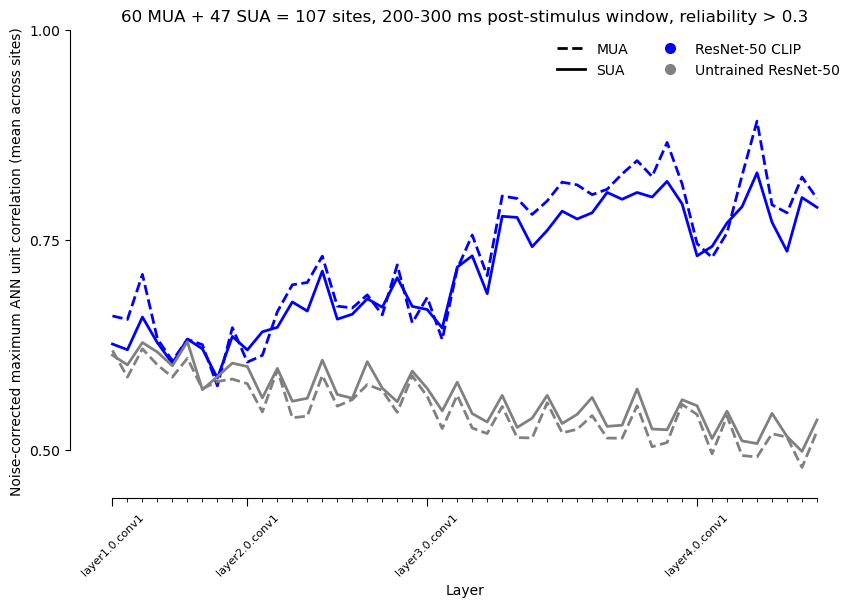

In [103]:
# Plot correlation on y-axis and layer_idx on x-axis. different lines for each site, and color MUA/SUA with different colors
fig, ax = plt.subplots(figsize=(10, 6))
colors_dict = {
    'MUA': 'blue',
    'SUA': 'red'
}
layer_names = model_considered_layers
mask_MUA = [label == 'MUA' for label in source_labels]
mask_SUA = [label == 'SUA' for label in source_labels]
n_sites, n_layers = layer_max_corrs.shape
# Individual sites
# for i in range(n_sites):
#     max_corr = layer_max_corrs[i]
#     label = source_labels[i]
#     ax.plot(max_corr.cpu().numpy(), '-', color=colors_dict.get(label, 'black'), alpha=0.1)
# Plot thick mean across all MUAs and SUAs
# CLIP (blue)
ax.plot(layer_max_corrs[mask_MUA].mean(axis=0).cpu().numpy(), '--', color='blue', linewidth=2)
ax.plot(layer_max_corrs[mask_SUA].mean(axis=0).cpu().numpy(), '-', color='blue', linewidth=2)

# Untrained baseline (gray)
ax.plot(baseline_layer_max_corrs[mask_MUA].mean(axis=0).cpu().numpy(), '--', color='gray', linewidth=2)
ax.plot(baseline_layer_max_corrs[mask_SUA].mean(axis=0).cpu().numpy(), '-', color='gray', linewidth=2)

# Custom legend: line style = unit type, dot color = model
custom_handles = [
    plt.Line2D([0], [0], color='black', linestyle='--', linewidth=2, label='MUA'),
    plt.Line2D([0], [0], color='black', linestyle='-', linewidth=2, label='SUA'),
    plt.Line2D([0], [0], marker='o', color='blue', linestyle='None', markersize=7, label='ResNet-50 CLIP'),
    plt.Line2D([0], [0], marker='o', color='gray', linestyle='None', markersize=7, label='Untrained ResNet-50'),
]
ax.legend(handles=custom_handles, frameon=False, ncol=2)
plt.ylim(0, 1)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.gca().spines['left'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_position(('outward', 5))
plt.gca().set_yticks([0.5, 0.75, 1])
plt.gca().spines['left'].set_bounds(0.5, 1)
plt.gca().set_ylim(0.45, 1)
plt.gca().spines['bottom'].set_bounds(0, n_layers-1)
# Plot xticks only if layer_name has conv1 in it
major_tick_positions = [i for i, name in enumerate(layer_names) if '0.conv1' in name]
minor_tick_positions = [i for i in range(n_layers) if i not in major_tick_positions]

ax.set_xticks(major_tick_positions)
ax.set_xticklabels([layer_names[i] for i in major_tick_positions], rotation=45, fontsize=8)

ax.set_xticks(minor_tick_positions, minor=True)
ax.tick_params(axis='x', which='major', length=6)
ax.tick_params(axis='x', which='minor', length=3, labelbottom=False)
plt.xlabel('Layer')
plt.ylabel('Noise-corrected maximum ANN unit correlation (mean across sites)')
title_str = ''
unique_labels, counts = np.unique(source_labels, return_counts=True)
for i, (unique_label, count) in enumerate(zip(unique_labels, counts)):
    title_str += f'{count} {unique_label}'
    if i == 0:
        title_str += ' + '
title_str += f' = {np.sum(counts)} sites, 200-300 ms post-stimulus window, reliability > {reliability_threshold}'
plt.title(title_str)
plt.show()

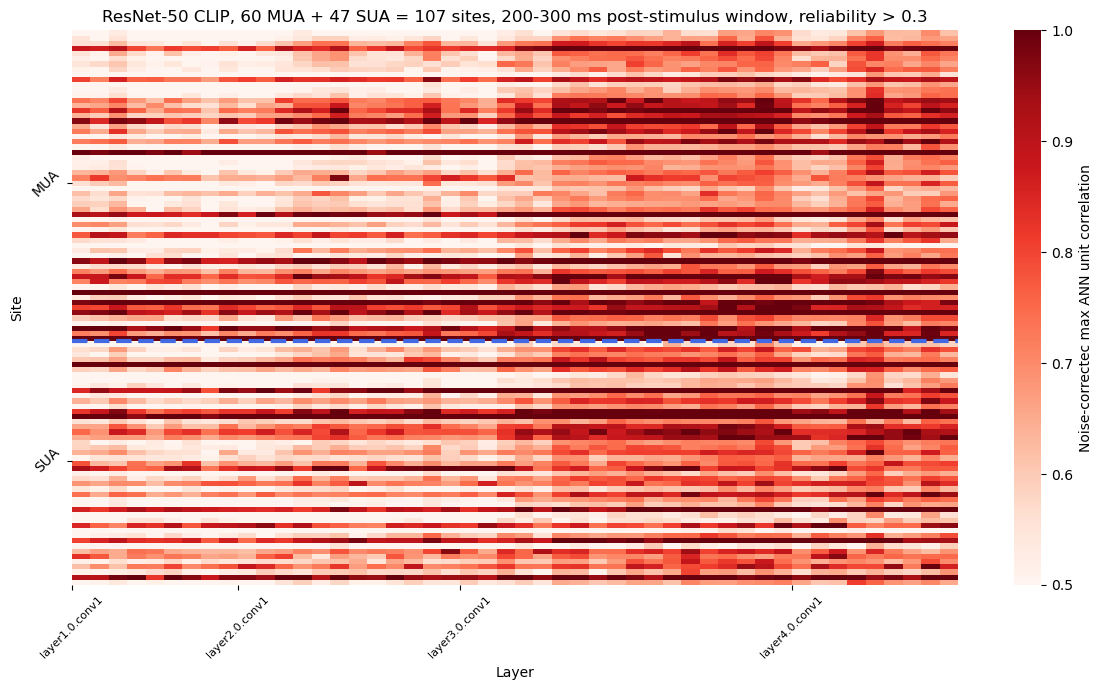

In [107]:
import seaborn as sns

# Create a heatmap from layer_max_corrs, add a separator line between MUA/SUA
# Prepare data
corrs_np = layer_max_corrs.cpu().numpy()
fig, ax = plt.subplots(figsize=(12, 7))
sns.heatmap(
    corrs_np,
    cmap='Reds',
    vmin=0.5, vmax=1,
    cbar_kws={'label': 'Noise-correctec max ANN unit correlation'},
    ax=ax
)

# Add separator line between MUA and SUA
labels = np.array(source_labels)
if np.any(labels == 'MUA') and np.any(labels == 'SUA'):
    sep_idx = np.where(labels == 'SUA')[0][0]
    ax.axhline(sep_idx, linestyle='--', color='royalblue', linewidth=3)

# Set y-ticks to "MUA" or "SUA" only
yticks_pos = []
yticks_labels = []
if np.any(labels == 'MUA'):
    yticks_pos.append(np.where(labels == 'MUA')[0][0] + (np.where(labels == 'MUA')[0][-1] - np.where(labels == 'MUA')[0][0]) / 2)
    yticks_labels.append('MUA')
if np.any(labels == 'SUA'):
    yticks_pos.append(np.where(labels == 'SUA')[0][0] + (np.where(labels == 'SUA')[0][-1] - np.where(labels == 'SUA')[0][0]) / 2)
    yticks_labels.append('SUA')
ax.set_yticks(yticks_pos)
ax.set_yticklabels(yticks_labels, rotation=45)

# Set x-ticks to only major layers (e.g., those with '0.conv1' in name)
major_tick_positions = [i for i, name in enumerate(layer_names) if '0.conv1' in name]
ax.set_xticks(major_tick_positions)
ax.set_xticklabels([layer_names[i] for i in major_tick_positions], rotation=45, fontsize=8)

ax.set_xlabel('Layer')
ax.set_ylabel('Site')
title_str = ''
unique_labels, counts = np.unique(source_labels, return_counts=True)
for i, (unique_label, count) in enumerate(zip(unique_labels, counts)):
    title_str += f'{count} {unique_label}'
    if i == 0:
        title_str += ' + '
title_str += f' = {np.sum(counts)} sites, 200-300 ms post-stimulus window, reliability > {reliability_threshold}'
ax.set_title(f'ResNet-50 CLIP, {title_str}')
plt.tight_layout()
plt.show()

Initialized resnet50random42 with seed = 42
Number of layers considered for the model resnet50random42: 48


  0%|          | 0/48 [00:00<?, ?it/s]

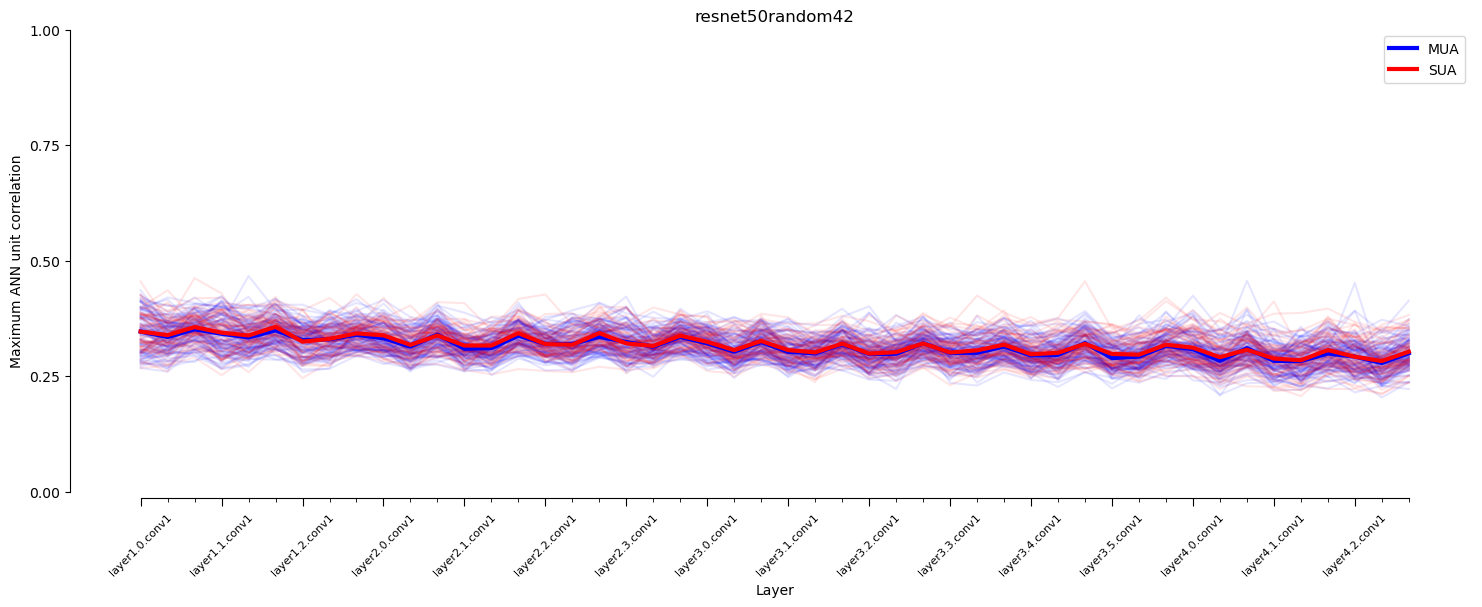

In [35]:
model = resnet50_random.get_model()
model_all_relevant_layers = model.relevant_layer_names
model_considered_layers = [layer for layer in model_all_relevant_layers if 'conv' in layer]
print(f'Number of layers considered for the model {model.name}: {len(model_considered_layers)}')
model_murty185_activations = model_utils.get_dataset_activations(
    MODELS_DIR,
    paths.MURTY185_DIR,
    model,
    model_considered_layers,
    'murty185',
)
model_murty185_activations = {k: v.flatten(start_dim=1).T for k, v in model_murty185_activations.items()}

layer_correlation_matrices = {}
layer_max_corrs = []
for layer_name, layer_acts in tqdm(model_murty185_activations.items()):
    X = model_murty185_activations[layer_name]
    # print(f"Example shapes - X: {X_example}, Y: {Y.shape}")
    XY_corr_matrix = get_correlation_matrix(X, Y)
    # print(f"Correlation matrix shape: {XY_corr_matrix.shape}")
    layer_correlation_matrices[layer_name] = XY_corr_matrix
    XY_maxcorr, XY_maxcorr_idxs = XY_corr_matrix.max(dim=0)
    layer_max_corrs.append(XY_maxcorr)

layer_max_corrs = torch.stack(layer_max_corrs).T
source_labels = source_df['label'].values

# Plot correlation on y-axis and layer_idx on x-axis. different lines for each site, and color MUA/SUA with different colors
fig, ax = plt.subplots(figsize=(18, 6))
colors_dict = {
    'MUA': 'blue',
    'SUA': 'red'
}
layer_names = model_considered_layers
mask_MUA = [label == 'MUA' for label in source_labels]
mask_SUA = [label == 'SUA' for label in source_labels]
n_sites, n_layers = layer_max_corrs.shape
for i in range(n_sites):
    max_corr = layer_max_corrs[i]
    label = source_labels[i]
    ax.plot(max_corr.cpu().numpy(), '-', color=colors_dict.get(label, 'black'), alpha=0.1)
# Plot thick mean across all MUAs and SUAs
ax.plot(layer_max_corrs[mask_MUA].mean(axis=0).cpu().numpy(), '-', color='blue', linewidth=3, label='MUA')
ax.plot(layer_max_corrs[mask_SUA].mean(axis=0).cpu().numpy(), '-', color='red', linewidth=3, label='SUA')
# Mock plot for legend
# plt.plot([], [], color='blue', marker='.', linestyle='-', label='MUA')
# plt.plot([], [], color='red', marker='.', linestyle='-', label='SUA')
plt.legend()
plt.ylim(0, 1)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.gca().spines['left'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_position(('outward', 5))
plt.gca().set_yticks([0, 0.25, 0.5, 0.75, 1])
plt.gca().spines['left'].set_bounds(0, 1)
plt.gca().set_ylim(0, 1)
plt.gca().spines['bottom'].set_bounds(0, n_layers-1)
# Plot xticks only if layer_name has conv1 in it
major_tick_positions = [i for i, name in enumerate(layer_names) if 'conv1' in name]
minor_tick_positions = [i for i in range(n_layers) if i not in major_tick_positions]

ax.set_xticks(major_tick_positions)
ax.set_xticklabels([layer_names[i] for i in major_tick_positions], rotation=45, fontsize=8)

ax.set_xticks(minor_tick_positions, minor=True)
ax.tick_params(axis='x', which='major', length=6)
ax.tick_params(axis='x', which='minor', length=3, labelbottom=False)
plt.xlabel('Layer')
plt.ylabel('Maximum ANN unit correlation')
plt.title(f'{model.name}')
plt.show()

Number of layers considered for the model resnet50imagenet1kv2: 48


100%|██████████| 1/1 [00:19<00:00, 19.81s/it]


  0%|          | 0/48 [00:00<?, ?it/s]

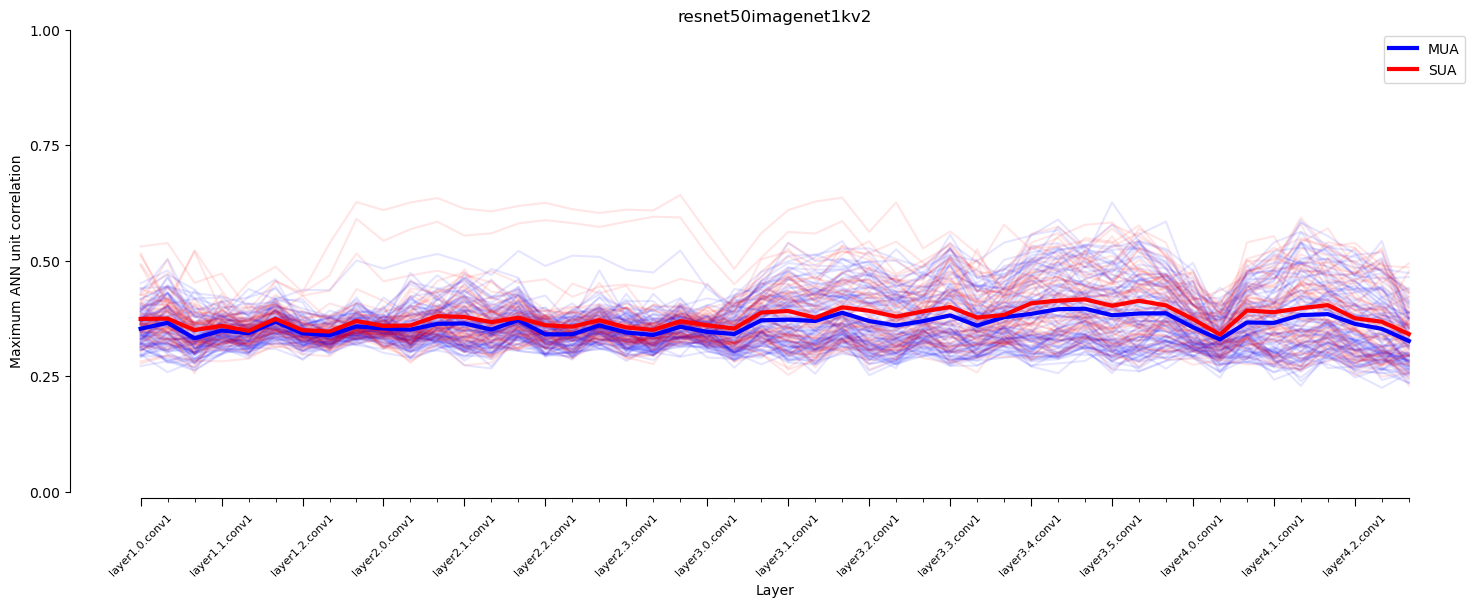

In [9]:
model = resnet50_imagenet1kv2.get_model()
model_all_relevant_layers = model.relevant_layer_names
model_considered_layers = [layer for layer in model_all_relevant_layers if 'conv' in layer]
print(f'Number of layers considered for the model {model.name}: {len(model_considered_layers)}')
model_murty185_activations = model_utils.get_dataset_activations(
    MODELS_DIR,
    paths.MURTY185_DIR,
    model,
    model_considered_layers,
    'murty185',
)
model_murty185_activations = {k: v.flatten(start_dim=1).T for k, v in model_murty185_activations.items()}

layer_correlation_matrices = {}
layer_max_corrs = []
for layer_name, layer_acts in tqdm(model_murty185_activations.items()):
    X = model_murty185_activations[layer_name]
    # print(f"Example shapes - X: {X_example}, Y: {Y.shape}")
    XY_corr_matrix = get_correlation_matrix(X, Y)
    # print(f"Correlation matrix shape: {XY_corr_matrix.shape}")
    layer_correlation_matrices[layer_name] = XY_corr_matrix
    XY_maxcorr, XY_maxcorr_idxs = XY_corr_matrix.max(dim=0)
    layer_max_corrs.append(XY_maxcorr)

layer_max_corrs = torch.stack(layer_max_corrs).T
source_labels = source_df['label'].values

# Plot correlation on y-axis and layer_idx on x-axis. different lines for each site, and color MUA/SUA with different colors
fig, ax = plt.subplots(figsize=(18, 6))
colors_dict = {
    'MUA': 'blue',
    'SUA': 'red'
}
layer_names = model_considered_layers
mask_MUA = [label == 'MUA' for label in source_labels]
mask_SUA = [label == 'SUA' for label in source_labels]
n_sites, n_layers = layer_max_corrs.shape
for i in range(n_sites):
    max_corr = layer_max_corrs[i]
    label = source_labels[i]
    ax.plot(max_corr.cpu().numpy(), '-', color=colors_dict.get(label, 'black'), alpha=0.1)
# Plot thick mean across all MUAs and SUAs
ax.plot(layer_max_corrs[mask_MUA].mean(axis=0).cpu().numpy(), '-', color='blue', linewidth=3, label='MUA')
ax.plot(layer_max_corrs[mask_SUA].mean(axis=0).cpu().numpy(), '-', color='red', linewidth=3, label='SUA')
# Mock plot for legend
# plt.plot([], [], color='blue', marker='.', linestyle='-', label='MUA')
# plt.plot([], [], color='red', marker='.', linestyle='-', label='SUA')
plt.legend()
plt.ylim(0, 1)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.gca().spines['left'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_position(('outward', 5))
plt.gca().set_yticks([0, 0.25, 0.5, 0.75, 1])
plt.gca().spines['left'].set_bounds(0, 1)
plt.gca().set_ylim(0, 1)
plt.gca().spines['bottom'].set_bounds(0, n_layers-1)
# Plot xticks only if layer_name has conv1 in it
major_tick_positions = [i for i, name in enumerate(layer_names) if 'conv1' in name]
minor_tick_positions = [i for i in range(n_layers) if i not in major_tick_positions]

ax.set_xticks(major_tick_positions)
ax.set_xticklabels([layer_names[i] for i in major_tick_positions], rotation=45, fontsize=8)

ax.set_xticks(minor_tick_positions, minor=True)
ax.tick_params(axis='x', which='major', length=6)
ax.tick_params(axis='x', which='minor', length=3, labelbottom=False)
plt.xlabel('Layer')
plt.ylabel('Maximum ANN unit correlation')
plt.title(f'{model.name}')
plt.show()

In [144]:
X_example = model_murty185_activations['layer1.2.conv2']
Y_example = torch.Tensor(np.nanmean(np.nanmean(neurons_data, axis=-1), axis=-1))
print(f"Example shapes - X: {X_example}, Y: {Y_example.shape}")
XY_corr_matrix = get_correlation_matrix(X_example, Y_example)
print(f"Correlation matrix shape: {XY_corr_matrix.shape}")
XY_maxcorr, XY_maxcorr_idxs = XY_corr_matrix.max(dim=0)
XY_maxcorr

Example shapes - X: tensor([[-0.0774,  0.0273, -0.0944,  ..., -0.0129, -0.1004, -0.0179],
        [-0.1065, -0.1003, -0.0708,  ..., -0.0527,  0.0119, -0.0280],
        [-0.0680, -0.0461,  0.0330,  ..., -0.0414, -0.0105, -0.0640],
        ...,
        [ 0.1959,  0.0622,  0.1227,  ..., -0.0352,  0.1081,  0.0669],
        [ 0.0542,  0.1041,  0.1790,  ...,  0.0409,  0.1922,  0.1174],
        [-0.0591, -0.0031,  0.1496,  ..., -0.0771,  0.1083,  0.0536]],
       device='mps:0'), Y: torch.Size([155, 185])
Correlation matrix shape: torch.Size([200704, 155])


tensor([0.3189, 0.3285, 0.3419, 0.2941, 0.3769, 0.3053, 0.3317, 0.3161, 0.3317,
        0.2930, 0.3494, 0.3122, 0.3579, 0.3134, 0.3301, 0.3178, 0.2992, 0.3643,
        0.3080, 0.3288, 0.3129, 0.3211, 0.3314, 0.3614, 0.3334, 0.3038, 0.3329,
        0.3498, 0.3157, 0.3242, 0.3384, 0.3408, 0.3217, 0.3921, 0.3075, 0.3544,
        0.2931, 0.3358, 0.3305, 0.3034, 0.3195, 0.3120, 0.3385, 0.3272, 0.3300,
        0.3292, 0.3564, 0.3304, 0.3262, 0.3306, 0.3080, 0.3373, 0.2970, 0.3281,
        0.3258, 0.3659, 0.3287, 0.3358, 0.3286, 0.3679, 0.3158, 0.3339, 0.2838,
        0.3547, 0.3670, 0.3224, 0.3384, 0.3237, 0.3560, 0.3528, 0.3986, 0.3329,
        0.3370, 0.3416, 0.3062, 0.3060, 0.3271, 0.3108, 0.3177, 0.3476, 0.3302,
        0.3063, 0.3306, 0.3370, 0.3230, 0.3005, 0.3342, 0.3066, 0.3024, 0.3002,
        0.3148, 0.3205, 0.3333, 0.3239, 0.3351, 0.3151, 0.3279, 0.3362, 0.3269,
        0.3791, 0.2992, 0.3242, 0.3691, 0.3327, 0.3379, 0.3435, 0.3115, 0.3244,
        0.3353, 0.3270, 0.3332, 0.3081, 

# Figuring out the time bins

In [2]:
data_dir = '/Users/adipani3/datasets/intracranial/A4'
assert os.path.exists(f'{data_dir}/processed')
neurons_data = np.load(f'{data_dir}/processed/NetSpikeRate_Z_norm_per_channel_interval_processed.npy')
source_df = pd.read_csv(f'{data_dir}/processed/source_info.csv')
image_info_df = pd.read_csv(f'{data_dir}/processed/image_info.csv')
Y = torch.Tensor(neurons_data)
print(Y.shape)

# Add another column for original_image_idx, convert image1.bmp	-> 1 integer
image_info_df['original_image_idx'] = image_info_df['original_image_name'].str.extract(r'(\d+)').astype(int)

# Sort image_info_df based on original_image_name
image_info_df_sorted = image_info_df.sort_values(by='original_image_idx')

m185_labels = murty185.LABELS
labels_intervals_info = []
old_label = m185_labels[0]
old_idx = 0
for lbl_idx, lbl in enumerate(m185_labels):
    if lbl != old_label:
        labels_intervals_info.append((old_label, old_idx+(lbl_idx-old_idx)/2, lbl_idx))
        old_label = lbl
        old_idx = lbl_idx
labels_intervals_info.append((old_label, old_idx+(len(m185_labels)-old_idx)/2, len(m185_labels)))

torch.Size([155, 185, 9, 70])


## Example raster map

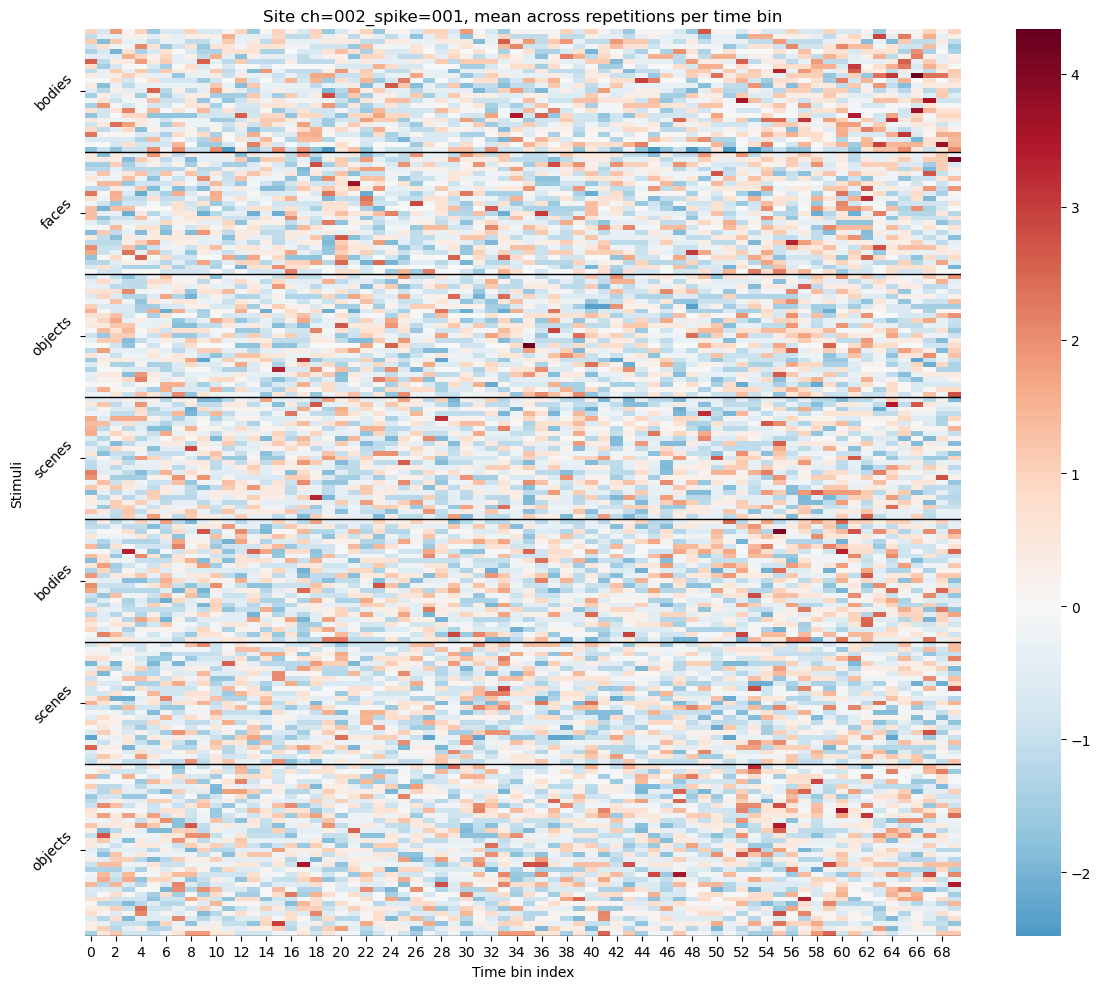

In [18]:
Y_repmean = torch.nanmean(Y, dim=2)
site_idx = 1
site_data = Y_repmean[site_idx]

plt.figure(figsize=(12, 10))
ax = sns.heatmap(site_data, cmap='RdBu_r', center=0)

# --- ticks and labels ---
tick_positions = [mid for (_, mid, _) in labels_intervals_info]
tick_labels = [label for (label, _, _) in labels_intervals_info]

ax.set_yticks(tick_positions)
ax.set_yticklabels(tick_labels, rotation=45, ha='right')

# --- vertical boundary lines ---
for (_, _, end) in labels_intervals_info:
    ax.axhline(end, color='black', linewidth=1)

plt.ylabel('Stimuli')
plt.xlabel('Time bin index')

plt.title(f'Site {source_df.iloc[site_idx]["key"]}, mean across repetitions per time bin')
plt.tight_layout()
plt.show()

## Response dynamics

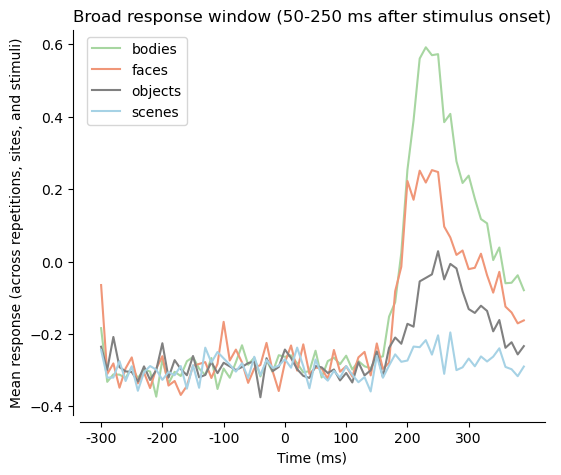

In [31]:
fig, ax = plt.subplots(figsize=(6, 5))
category_colors = {
    'faces': '#f09678',
    'scenes': '#a6d2e5',
    'bodies': '#a7d6a1',
    'objects': '#808080',
}
sitemean_data = torch.nanmean(torch.nanmean(Y, dim=2), axis=0)
n_timebins = Y.shape[-1]

# Take mean per time bin across all stimuli of the same category
for category in np.unique(m185_labels):
    category_mask = (np.array(m185_labels) == category)
    category_data = sitemean_data[category_mask].mean(axis=0)
    ax.plot(category_data, '-', color=category_colors.get(category, 'black'), label=f'{category}')
# plt.axvline(x=35, color='k', linestyle='--')
# plt.axvline(x=55, color='k', linestyle='--')
xticks_all = list(range(n_timebins))
xtick_labels = np.array([i*10 for i in xticks_all]) - 300
xtick_idxs = [idx for idx, xtl in enumerate(xtick_labels) if xtl%100 == 0]
plt.xticks(ticks=np.array(xticks_all)[xtick_idxs], labels=np.array(xtick_labels)[xtick_idxs])
plt.legend()
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.gca().spines['left'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_position(('outward', 5))
plt.xlabel('Time (ms)')
plt.ylabel('Mean response (across repetitions, sites, and stimuli)')
plt.title('Broad response window (50-250 ms after stimulus onset)')
plt.show()

## Relaibilities

In [4]:
data_binned = {
    'stimulus onset\n(0-400 ms)': torch.nanmean(Y[:, :, :, 30:], axis=-1),
    'broad window\n(50-250 ms)': torch.nanmean(Y[:, :, :, 35:56], axis=-1),
    'narrow window\n(200-300 ms)': torch.nanmean(Y[:, :, :, 50:60], axis=-1),
}
relaibilities_binned = {}
for bin_label, bin_data in data_binned.items():
    relaibilities_binned[bin_label], _ = rel_utils.get_neuron_wise_splithalf_correlation(bin_data)

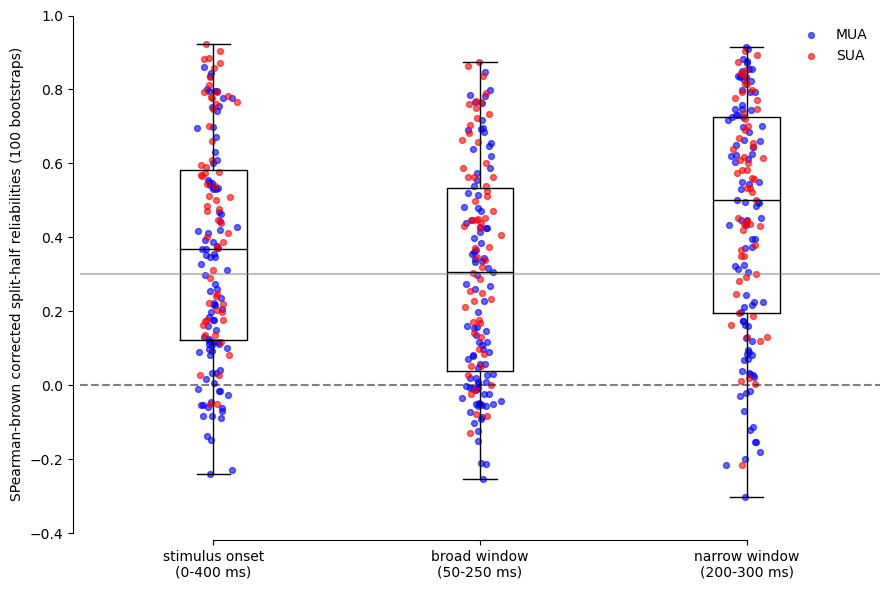

In [22]:
source_labels = source_df['label'].values
# For each bin type, plot a boxplot for reliabilities
# Also plot a scatter plot of points, and color based on the label (MUA/SUA)
plt.figure(figsize=(9, 6))

bin_labels = list(relaibilities_binned.keys())
colors_dict = {'MUA': 'blue', 'SUA': 'red'}
x_positions = np.arange(len(bin_labels))

# Boxplots (all sites combined) in one axis
box_data = [relaibilities_binned[bl] for bl in bin_labels]
plt.boxplot(box_data, positions=x_positions, widths=0.25, showfliers=False, medianprops=dict(color='black'))

# Overlay scatter points, colored by MUA/SUA
for i, bl in enumerate(bin_labels):
    vals = relaibilities_binned[bl]
    for lab in ['MUA', 'SUA']:
        mask = source_labels == lab
        x_jitter = np.random.normal(loc=i, scale=0.03, size=mask.sum())
        plt.scatter(
            x_jitter,
            vals[mask],
            s=18,
            alpha=0.6,
            color=colors_dict[lab],
            label=lab if i == 0 else None
        )
plt.axhline(y=0, color='k', linestyle='--', alpha=0.5)
plt.axhline(y=0.3, color='gray', linestyle='-', alpha=0.5)
plt.xticks(x_positions, bin_labels, rotation=20, ha='right')
plt.ylabel('SPearman-brown corrected split-half reliabilities (100 bootstraps)')
plt.ylim(-0.4, 1.0)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.gca().spines['left'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_bounds(0, 2)
plt.legend(frameon=False)
plt.tight_layout()
plt.show()

# Dev

In [25]:
data_dir = '/Users/adipani3/datasets/intracranial/A4'
os.makedirs(f'{data_dir}/processed', exist_ok=True)
filename = f'{data_dir}/processed/NetSpikeRate_Z_norm_per_channel_interval.h5'

## Explore images

In [ ]:
all_image_files = os.listdir(f'{data_dir}/images')
print(f'Number of image files in {data_dir}/images: {len(all_image_files)}')
image_files_considered = [f for f in all_image_files if f.endswith(('.bmp'))]
image_files_considered.remove('001.bmp') # Remove fixation cross
print(f'Number of image files considered: {len(image_files_considered)}')

Number of image files in /Users/adipani3/datasets/intracranial/A4/images: 1103
Number of image files considered: 870


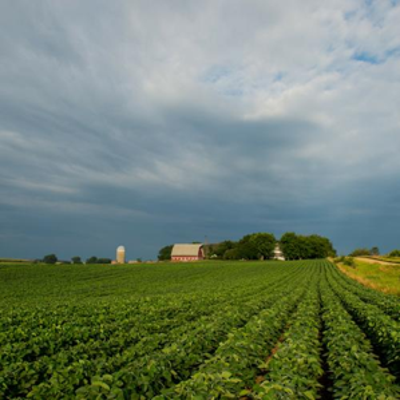

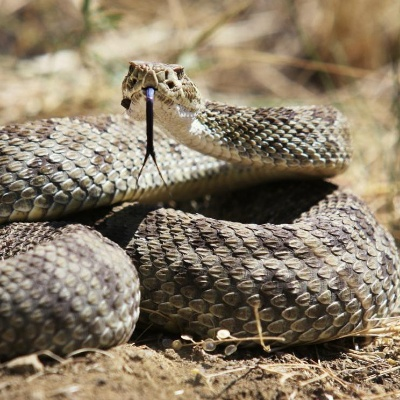

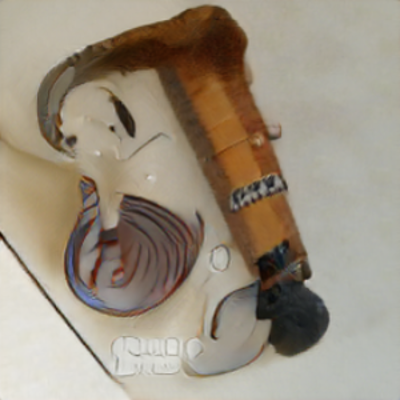

In [29]:
custom_ds = custom.CustomDataset(
    root_dir=f'{data_dir}/images',
    image_names=image_files_considered,
    dataset_name='intracranial_A4',
    transform=model.transforms
)

# Show a few images
random_idxs = np.random.choice(len(image_files_considered), size=3, replace=False)
for random_idx in random_idxs:
    img = Image.open(f'{data_dir}/images/{image_files_considered[random_idx]}')
    display(img)

In [34]:
acts = model.generate_dataset_activations(
    model_considered_layers,
    custom_ds,
    save_dir=f'{MODELS_DIR}/{model.name}/{custom_ds.name}/activations',
    batch_size=256,
    device='mps',
    num_workers=1
)

100%|██████████| 4/4 [00:49<00:00, 12.45s/it]


## Exploring data

### imageMapping

In [64]:
imageMapping = sio.loadmat(f'{data_dir}/imageMapping.mat')
set_names, image_names, image_file_names = [], [], []
n_images_possible = len(imageMapping['mappingInfo'])
print(f'Total number of entries: {n_images_possible}')
for info_idx, img_info in enumerate(imageMapping['mappingInfo']):
    set_names.append(img_info[0].item())
    image_names.append(img_info[1].item())
    if img_info[1].item() == 'ant_10s.bmp':
        print(img_info[2].item())
    image_file_names.append(img_info[2].item())
print(f'Unique set names: {np.unique(set_names, return_counts=True)}')
print(f'Number of unique image names: {len(np.unique(image_names))}')
print(f'Number of unique image file names: {len(np.unique(image_file_names))}')
# Image file names missing?
# for i_ in range(1, n_images_possible+1):
#     if f'{i_:03d}.bmp' not in image_file_names:
#         print(f'{i_:02d}.bmp')

Total number of entries: 1050
460.bmp
460.bmp
Unique set names: (array(['set1', 'set10', 'set11', 'set2', 'set3', 'set4', 'set5', 'set6',
       'set7', 'set8', 'set9'], dtype='<U5'), array([186,  73,  73,  90,  80,  70, 165,  36,  90,  90,  97]))
Number of unique image names: 703
Number of unique image file names: 867


In [85]:
set1_image_names, set1_image_file_names = [], []
for info_idx, img_info in enumerate(imageMapping['mappingInfo']):
    if img_info[0].item() == 'set1':
        set1_image_names.append(img_info[1].item())
        set1_image_file_names.append(img_info[2].item())

In [88]:
set1_image_names

['distractor.bmp',
 'image1.bmp',
 'image10.bmp',
 'image100.bmp',
 'image101.bmp',
 'image102.bmp',
 'image103.bmp',
 'image104.bmp',
 'image105.bmp',
 'image106.bmp',
 'image107.bmp',
 'image108.bmp',
 'image109.bmp',
 'image11.bmp',
 'image110.bmp',
 'image111.bmp',
 'image112.bmp',
 'image113.bmp',
 'image114.bmp',
 'image115.bmp',
 'image116.bmp',
 'image117.bmp',
 'image118.bmp',
 'image119.bmp',
 'image12.bmp',
 'image120.bmp',
 'image121.bmp',
 'image122.bmp',
 'image123.bmp',
 'image124.bmp',
 'image125.bmp',
 'image126.bmp',
 'image127.bmp',
 'image128.bmp',
 'image129.bmp',
 'image13.bmp',
 'image130.bmp',
 'image131.bmp',
 'image132.bmp',
 'image133.bmp',
 'image134.bmp',
 'image135.bmp',
 'image136.bmp',
 'image137.bmp',
 'image138.bmp',
 'image139.bmp',
 'image14.bmp',
 'image140.bmp',
 'image141.bmp',
 'image142.bmp',
 'image143.bmp',
 'image144.bmp',
 'image145.bmp',
 'image146.bmp',
 'image147.bmp',
 'image148.bmp',
 'image149.bmp',
 'image15.bmp',
 'image150.bmp',
 'i

### labels_images

In [ ]:
# imageLabels = sio.loadmat(f'{data_dir}/labels_images.mat')

# Converted to csv in MATLAB
imageLabels_df = pd.read_csv(f'{data_dir}/labels.csv')

### PinLayoutUtah

In [74]:
def pin_layout_utah(array_id):
    """
    Returns the 10x10 channel layout for a Utah array.

    Parameters
    ----------
    array_id : int
        Array number (1, 2, 3, 4, or 5)

    Returns
    -------
    ch_layout : np.ndarray
        10x10 array with channel numbers and np.nan in corners
    """

    if array_id == 1:
        ch_layout = np.array([
            [np.nan, 79, 78, 72, 51, 64, 44, 23, 3, np.nan],
            [95, 77, 90, 70, 49, 62, 42, 21, 1, 16],
            [93, 75, 88, 68, 47, 60, 40, 19, 32, 14],
            [91, 73, 86, 66, 45, 58, 38, 17, 30, 12],
            [89, 71, 84, 63, 43, 56, 33, 15, 28, 10],
            [87, 69, 82, 61, 41, 54, 34, 13, 26, 8],
            [85, 67, 80, 59, 39, 52, 31, 11, 24, 6],
            [83, 65, 78, 57, 37, 50, 32, 9, 22, 4],
            [81, 96, 76, 55, 35, 48, 27, 7, 20, 2],
            [np.nan, 94, 74, 53, 33, 46, 31, 5, 18, np.nan]
        ])

    elif array_id in [2, 3, 4, 5]:
        ch_layout = np.array([
            [np.nan, 79, 92, 72, 51, 64, 44, 23, 3, np.nan],
            [95, 77, 90, 70, 49, 62, 42, 21, 1, 16],
            [93, 75, 88, 68, 47, 60, 40, 19, 32, 14],
            [91, 73, 86, 66, 45, 58, 38, 17, 30, 12],
            [89, 71, 84, 63, 43, 56, 36, 15, 28, 10],
            [87, 69, 82, 61, 41, 54, 34, 13, 26, 8],
            [85, 67, 80, 59, 39, 52, 31, 11, 24, 6],
            [83, 65, 78, 57, 37, 50, 29, 9, 22, 4],
            [81, 96, 76, 55, 35, 48, 27, 7, 20, 2],
            [np.nan, 94, 74, 53, 33, 46, 25, 5, 18, np.nan]
        ])
    else:
        raise ValueError("array_id must be 1, 2, 3, 4, or 5")

    return ch_layout

### trialnumsA4_D4_set1

In [75]:
trailNums = sio.loadmat(f'{data_dir}/trialnumsA4_D4_set1.mat')

In [76]:
trailNums

{'__header__': b'MATLAB 5.0 MAT-file, Platform: GLNXA64, Created on: Tue Mar 24 16:47:12 2026',
 '__version__': '1.0',
 '__globals__': [],
 'trialnpercond': array([[(array([[(array([[   9,  328,  517,  563,  658,  847, 1150, 1358, 1487]],
                       dtype=uint16), array([[  30,  356,  463,  753,  840, 1019, 1300]], dtype=uint16), array([[ 106,  241,  499,  561,  626,  894, 1024, 1349, 1464]],
                       dtype=uint16), array([[ 102,  359,  401,  590,  639,  845, 1109, 1287]], dtype=uint16), array([[ 135,  194,  556,  634,  901, 1087, 1221, 1505]], dtype=uint16), array([[  44,  226,  459,  650,  859, 1102, 1294, 1404]], dtype=uint16), array([[ 161,  270,  544,  568,  659,  881, 1111, 1263, 1382]],
                       dtype=uint16), array([[  54,  202,  395,  786,  833, 1112, 1183, 1396]], dtype=uint16), array([[ 150,  340,  394,  637,  880, 1070, 1268, 1397]], dtype=uint16), array([[ 160,  302,  415,  629,  945, 1026, 1256, 1496]], dtype=uint16), array([[ 178, 

### Neural responses: NetSpikeRateA4_D4_set1_combined_10ms

In [4]:
spike_data = sio.loadmat(f'{data_dir}/NetSpikeRateA4_D4_set1_combined_10ms.mat')

In [ ]:
# spike_data['NetSpikeRate_Z_norm_per_channel_interval']


In [7]:
print("=== Loading HDF5 File ===\n")
 
with h5py.File(filename, 'r') as f:
    # Load first spike
    spike_data = f['/ch_001/spike_001'][:]
    print(f"Spike shape: {spike_data.shape}")
    print(f"Interpretation: (num_images=186, width=70, max_reps=9)\n")
    
    # Check for NaNs
    num_nans = np.isnan(spike_data).sum()
    total_elements = spike_data.size
    print(f"Total elements: {total_elements}")
    print(f"NaN elements: {num_nans}")
    print(f"Valid data elements: {total_elements - num_nans}\n")
    
    # Stats per image
    print("Stats for each image in spike_001 (first 10 images):")
    for img_idx in range(10):
        img_data = spike_data[img_idx, :, :]  # (70, 9)
        valid_data = img_data[~np.isnan(img_data)]
        if len(valid_data) > 0:
            print(f"  Image {img_idx+1:03d}: shape={img_data.shape}, "
                  f"valid_vals={len(valid_data)}, "
                  f"mean={np.nanmean(img_data):.4f}, "
                  f"std={np.nanstd(img_data):.4f}")
    
    print(f"\n=== Quick Access Examples ===\n")
    
    # Example 1: Get a specific image (all reps and width)
    img_42 = spike_data[41, :, :]  # Image 42 (0-indexed), all width and reps
    print(f"Image 42: shape={img_42.shape} (width x reps)")
    print(f"  Mean: {np.nanmean(img_42):.4f}")
    print(f"  Std: {np.nanstd(img_42):.4f}\n")
    
    # Example 2: Remove NaN padding from an image
    valid_reps = ~np.isnan(img_42).all(axis=0)  # Check across width dimension
    img_42_clean = img_42[:, valid_reps]  # Keep only valid reps
    print(f"Image 42 (after removing NaN padding): shape={img_42_clean.shape}")
    print(f"  Original reps: 9, Valid reps: {img_42_clean.shape[1]}\n")
    
    # Example 3: Get all images at a specific repetition
    rep_0 = spike_data[:, :, 0]  # First repetition, all images
    print(f"First repetition (rep 0), all images: shape={rep_0.shape} (images x width)")
    print(f"  Mean: {np.nanmean(rep_0):.4f}\n")
    
    # Example 4: Average across repetitions for each image
    mean_per_image = np.nanmean(spike_data, axis=(1, 2))  # Average over width and reps
    print(f"Mean value per image (averaged over width and reps): shape={mean_per_image.shape}")
    print(f"  First 10 image means: {mean_per_image[:10]}\n")
    
    # Example 5: Loop through all channels and spikes
    print("=== Summary of all data ===\n")
    total_spikes = 0
    for ch_idx, ch_key in enumerate(list(f.keys())[:5]):  # Show first 5 channels
        ch_group = f[ch_key]
        spike_list = list(ch_group.keys())
        total_spikes += len(spike_list)
        print(f"{ch_key}: {len(spike_list)} spikes")
    
    # Count all
    all_channels = list(f.keys())
    all_spikes = sum(len(list(f[ch].keys())) for ch in all_channels)
    print(f"...\nTotal channels: {len(all_channels)}")
    print(f"Total spikes: {all_spikes}\n")
 
print("=== File loaded successfully! ===")
print("\nData structure:")
print("  spike_data[image_idx, width_idx, rep_idx]")
print("  Example: spike_data[0, :, :] = first image (70 width x 9 reps)")

=== Loading HDF5 File ===

Spike shape: (186, 70, 9)
Interpretation: (num_images=186, width=70, max_reps=9)

Total elements: 117180
NaN elements: 10850
Valid data elements: 106330

Stats for each image in spike_001 (first 10 images):
  Image 001: shape=(70, 9), valid_vals=630, mean=-0.5529, std=1.9806
  Image 002: shape=(70, 9), valid_vals=490, mean=-0.2845, std=2.1938
  Image 003: shape=(70, 9), valid_vals=630, mean=-0.0357, std=2.3640
  Image 004: shape=(70, 9), valid_vals=560, mean=-0.5968, std=1.7213
  Image 005: shape=(70, 9), valid_vals=560, mean=-0.2571, std=2.4706
  Image 006: shape=(70, 9), valid_vals=560, mean=0.2890, std=2.9699
  Image 007: shape=(70, 9), valid_vals=630, mean=-0.0537, std=2.5495
  Image 008: shape=(70, 9), valid_vals=560, mean=0.4411, std=2.8158
  Image 009: shape=(70, 9), valid_vals=560, mean=-0.3982, std=2.0546
  Image 010: shape=(70, 9), valid_vals=560, mean=-0.4075, std=2.0582

=== Quick Access Examples ===

Image 42: shape=(70, 9) (width x reps)
  Mean:

## Process data

### Image info

In [29]:
data_dir = '/Users/adipani3/datasets/intracranial/A4'
all_image_files = os.listdir(f'{data_dir}/images')
print(f'Number of image files in {data_dir}/images: {len(all_image_files)}')
image_files_considered = [f for f in all_image_files if f.endswith(('.bmp'))]
image_files_considered.remove('001.bmp') # Remove fixation cross
print(f'Number of image files considered: {len(image_files_considered)}')

# Image labels
image_labels_df = pd.read_csv(f'{data_dir}/processed/image_labels.csv')
# Set column names to 'image_index', 'label', 'category'
image_labels_df.columns = ['label', 'category']
# name index column as 'image_index'
image_labels_df.insert(0, 'image_index', range(0, len(image_labels_df)))
# set image_index as the index of the dataframe
image_labels_df.set_index('image_index', inplace=True)

# Image mapping to the original dataset
image_mapping_df = pd.read_csv(f'{data_dir}/processed/image_mapping.csv')
image_mapping_df = image_mapping_df[
    image_mapping_df['set_number'] == 'set1'
]
# set index column name to 'image_index'
image_mapping_df.insert(0, 'image_index', range(0, len(image_mapping_df)))
image_mapping_df.set_index('image_index', inplace=True)

# Choose only the rows that are in mapping (set 1: Murty185)
image_labels_df = image_labels_df.iloc[:len(image_mapping_df), :]

# Drop first row of both dataframes
image_mapping_df = image_mapping_df.iloc[1:, :]
image_labels_df = image_labels_df.iloc[1:, :]

# Join the two dataframes on the index
image_info_df = image_labels_df.join(image_mapping_df)

assert len(image_info_df) == 185, "Number of images in the dataset should be 185"
image_info_df.head()

image_info_df.to_csv(f'{data_dir}/processed/image_info.csv', index=False)

Number of image files in /Users/adipani3/datasets/intracranial/A4/images: 872
Number of image files considered: 870


### Neural responses

In [37]:
image_info_df = pd.read_csv(f'{data_dir}/processed/image_info.csv')
stimuli_original_murty185_mapping = np.zeros(len(image_info_df), dtype=int)
# Create mapping from intracrianl data order to original murty185 order
for i, row in image_info_df.iterrows():
    original_image_name = row['original_image_name']
    original_image_idx_1indexed = int(original_image_name.split('.')[0].replace('image', ''))
    stimuli_original_murty185_mapping[original_image_idx_1indexed-1] = i

In [120]:
Y = {}

with h5py.File(filename, 'r') as f:
    # Quick exploration commands:
    # 1. List all channels
    channels = list(f.keys())
    print(f"Channels: {channels[:5]}... (total: {len(channels)})")

    for channel in channels:
        spikes = list(f[channel].keys())
        for spike in spikes:
            data_ = f[f'{channel}/{spike}'][:]  # (186, 70, 9)
            # Remove the first image (fixation cross)
            data_ = data_[1:, :, :]
            # Transpose to (185, 9, 70), i.e. images x n_reps x n_timebins
            data_ = data_.transpose(0, 2, 1)
            # Order in the original Murty185 ordering
            data_ = data_[stimuli_original_murty185_mapping]
            if np.isnan(data_).all():
                print(f"Skipping {channel}/{spike}: all NaNs")
                continue
            Y[f'{channel.replace("_", "=")}_{spike.replace("_", "=")}'] = {
                'data': data_,
                'label': 'MUA' if spike == 'spike_001' else 'SUA'
            }

    # 2. List all spikes in a channel
    
    # print(f"Spikes in ch_001: {spikes_ch}")
    
    # # 3. Load any spike quickly
    # spike = f['/ch_050/spike_001'][:]  # (186, 70, 9)
    
    # # 4. Access patterns
    # img_1 = spike[0, :, :]          # Image 1: all width & reps (70 x 9)
    # rep_1 = spike[:, :, 0]          # Rep 1: all images & width (186 x 70)
    # pixel = spike[10, 20, 3]        # Single pixel (image 11, width 21, rep 4)
    
    # # 5. Handle NaNs
    # valid_pixels = ~np.isnan(spike)  # Boolean mask
    # spike_clean = spike[valid_pixels]  # Flatten to 1D array of valid values
    
    # # 6. Statistics
    # mean_spike = np.nanmean(spike)
    # std_spike = np.nanstd(spike)
    
    # # 7. Per-image stats
    # per_image_mean = np.nanmean(spike, axis=(1, 2))  # Mean per image
    # per_rep_mean = np.nanmean(spike, axis=(0, 1))    # Mean per repetition

# Sort keys, bring all spike=001 at first, i.e. ch=001_spike=001, ch=002_spike=001...
Y_MUAs, Y_SUAs = {},  {}
for key, value in Y.items():
    if key.split('_')[-1] == 'spike=001':
        Y_MUAs[key] = value
    else:
        Y_SUAs[key] = value
Y_sorted = {**Y_MUAs, **Y_SUAs}

Y_array = [value['data'] for value in Y_sorted.values()]
Y_array = np.stack(Y_array)

np.save(f'{data_dir}/processed/NetSpikeRate_Z_norm_per_channel_interval_processed.npy', Y_array)

# Convert labels info a df
labels = [value['label'] for value in Y_sorted.values()]
keys = [key for key in Y_sorted.keys()]
source_df = pd.DataFrame({'key': keys, 'label': labels})
source_df.to_csv(f'{data_dir}/processed/source_info.csv', index=False)

Channels: ['ch_001', 'ch_002', 'ch_003', 'ch_004', 'ch_005']... (total: 96)
Skipping ch_031/spike_001: all NaNs
